# Etapa 12 · Investigação dos achados

| | |
|---|---|
| **Pergunta** | Por que acontecem os três efeitos que as etapas mediram e não explicaram, e o que cada um ensina para o artigo? |
| **Entrada** | As respostas gravadas e os modelos das Etapas 10a, 10b, 10c, 11b e 11c (`entregas/` e o cache delas em `data/execucoes/`), os rótulos dos professores (`entregas/05a_professor_fechado/`, `entregas/11a_professor_aberto_maior/`) e as execuções novas desta etapa, gravadas por `especialista/experimentos/etapa12.py` em `data/execucoes/12_investigacao_dos_achados/`. |
| **Entrega** | `entregas/12_investigacao_dos_achados/`: para cada achado, as hipóteses, os testes, os números com intervalo e a conclusão (explicado, explicado em parte, não explicado); o plano gravado antes; a leitura única no teste; os artigos conferidos. |
| **Pronto quando** | o plano foi gravado antes de qualquer execução; cada hipótese do plano tem o seu teste feito e a sua leitura; o teste foi lido só como o plano fixou; cada explicação tem um artigo conferido na fonte, com o que ele sustenta e o que não; nada das outras etapas mudou. |

**É uma investigação depois dos resultados.** Tudo aqui é diagnóstico e exploratório: os efeitos já tinham sido vistos, e os testes foram escolhidos depois deles. Nenhuma decisão das etapas anteriores muda, e os modelos finais continuam os mesmos. O que parecer recomendação é recomendação para um próximo trabalho, não troca de receita.

**Método.** O plano (hipóteses, testes, o que contaria como confirmação ou refutação, e a leitura no teste de cada achado) foi gravado em `plano.json` antes de qualquer execução. A exploração é toda em `dev`, com os rótulos humanos. Cada comparação é a diferença pareada da média de 3 sementes, com intervalo de 95% por bootstrap de enunciados (2.000 sorteios), como em todas as etapas. O teste entra uma vez por achado, como o plano fixou.

**Artigos de apoio.** Cada um foi conferido na API do arXiv (título, primeiro autor, data) e o resumo foi lido; nenhum PDF foi aberto. O quadro, com o que cada resumo sustenta e o que não sustenta, está na seção 6.

- Arpit et al., *A Closer Look at Memorization in Deep Networks*, [arXiv 1706.05394](https://arxiv.org/abs/1706.05394)
- Zhang et al., *Understanding deep learning requires rethinking generalization*, [arXiv 1611.03530](https://arxiv.org/abs/1611.03530)
- Stanton et al., *Does Knowledge Distillation Really Work?*, [arXiv 2106.05945](https://arxiv.org/abs/2106.05945)
- Mosbach, Andriushchenko & Klakow, *On the Stability of Fine-tuning BERT*, [arXiv 2006.04884](https://arxiv.org/abs/2006.04884)
- Gupta et al., *Continual Pre-Training of Large Language Models: How to (re)warm your model?*, [arXiv 2308.04014](https://arxiv.org/abs/2308.04014)
- Abdaoui, Pradel & Sigel, *Load What You Need*, [arXiv 2010.05609](https://arxiv.org/abs/2010.05609); Ushio, Zhou & Camacho-Collados, *Vocabulary Trimming*, [arXiv 2305.15020](https://arxiv.org/abs/2305.15020)
- Bondarenko, Nagel & Blankevoort, *Understanding and Overcoming the Challenges of Efficient Transformer Quantization*, [arXiv 2109.12948](https://arxiv.org/abs/2109.12948)
- Kovaleva et al., *BERT Busters*, [arXiv 2105.06990](https://arxiv.org/abs/2105.06990); Dettmers et al., *LLM.int8()*, [arXiv 2208.07339](https://arxiv.org/abs/2208.07339)
- Wu et al., *Integer Quantization for Deep Learning Inference*, [arXiv 2004.09602](https://arxiv.org/abs/2004.09602); Jacob et al., [arXiv 1712.05877](https://arxiv.org/abs/1712.05877)
- Dutta et al., *Accuracy is Not All You Need*, [arXiv 2407.09141](https://arxiv.org/abs/2407.09141)

**Seções**

1. O plano, gravado antes
2. Achado 1: a poda do XLM-R nos alunos do cenário B
3. Achado 3: a INT8 dinâmica e a intenção
4. Achado 2: a INT8 estática e a semente que desaba
5. A leitura no teste
6. Os artigos
7. Nada das outras etapas mudou
8. Critério de pronto e resumo

In [1]:
import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.caminhos import ENTREGAS, RAIZ
from especialista.experimentos import etapa12 as e

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

BASE = e.pasta_da_etapa()           # data/execucoes/12_investigacao_dos_achados
CONTAS = e.pasta_das_contas()       # gravado por `python -m especialista.experimentos.etapa12 contas`
PASTA = e.pasta_da_entrega()
plano = e.plano()
ler = lambda nome: pd.read_csv(CONTAS / nome)
ler_json = lambda nome: json.loads((CONTAS / nome).read_text(encoding="utf-8"))
C1, PROF, CURVAS, TREINO, DD = (ler(f"achado1_{n}.csv") for n in ("comparacoes", "professor", "curvas", "treino", "diferenca_das_diferencas"))
CORTE = ler_json("achado1_corte.json")
P3, T3, ALT3, NOVE = (ler(f"achado3_{n}.csv") for n in ("partes", "trocas", "alternativas", "nove_modelos"))
R3 = ler_json("achado3_resumo.json")
FAIXAS, MED, ALT2 = (ler(f"achado2_{n}.csv") for n in ("faixas", "medidas", "alternativas"))
TESTE = ler_json("teste.json")

NOMES = {**e.NOMES}
CURTO = {e.B1: "B1 · Qwen3-14B", e.B2: "B2 · Qwen3-14B", e.B2_ANTIGO: "B2 · Qwen3-8B", e.ALUNO_A: "Aluno A", e.TETO: "Teto"}
MOMENTO = {"partida": "modelo de partida (sem poda)", "so_corte": "só o corte", "corte_e_reajuste": "corte e reajuste (receita da 10b)",
           "sem_corte_e_reajuste": "reajuste sem corte (controle)", "corte_e_reajuste_refeito": "corte e reajuste, refeito nesta etapa",
           "corte_e_reajuste_taxa_menor": "corte e reajuste com taxa 10× menor"}


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",").replace("-", "−")


def n(x):
    return f"{int(x):,}".replace(",", ".")


def ci(linha, casas=1, prefixo=""):
    """'−1,0 (−1,8 a −0,3)' a partir de uma linha com diferença e intervalo (em pontos)."""
    g = lambda k: linha[prefixo + k]
    f = lambda x: f"{x:+.{casas}f}".replace(".", ",").replace("-", "−")
    return f"{f(g('diferenca'))} ({f(g('ic_min'))} a {f(g('ic_max'))})"


def c1(aluno, depois, antes, metrica="exact_match", sub=None):
    """Uma linha das comparações do achado 1 (em dev)."""
    t = C1[(C1["aluno"] == aluno) & (C1["depois"] == depois) & (C1["antes"] == antes) & (C1["metrica"] == metrica)]
    t = t[t["subconjunto"].isna()] if sub is None else t[t["subconjunto"] == sub]
    assert len(t) == 1, (aluno, depois, antes, metrica, sub, len(t))
    return t.iloc[0]


def distinguivel(linha, prefixo=""):
    return linha[prefixo + "ic_min"] > 0 or linha[prefixo + "ic_max"] < 0

## 1. O plano, gravado antes

O plano foi escrito depois de ler os resumos e as decisões das etapas de origem e antes de rodar qualquer coisa nova ou de fazer qualquer conta nova sobre as respostas gravadas. A hora em que ele foi gravado fica comparada, abaixo, com a hora da primeira execução desta etapa.

In [2]:
arquivo_do_plano = BASE / "plano.json"
primeira_execucao = min(p.stat().st_mtime for p in BASE.glob("reajustes/*/*/*/semente_*/meta.json"))
for p in list(BASE.glob("onnx/*/*/semente_*/fp32/conferido.json")) + list(BASE.glob("estatica/*/*/semente_*/faixas.csv")):
    primeira_execucao = min(primeira_execucao, p.stat().st_mtime)
impressoes_antes = json.loads((BASE / "impressoes" / "impressoes_antes.json").read_text(encoding="utf-8"))["tirada_em"]
import hashlib
sha_do_plano = hashlib.sha256(arquivo_do_plano.read_bytes()).hexdigest()
plano_antes = arquivo_do_plano.stat().st_mtime < primeira_execucao
plano_intacto = sha_do_plano == (BASE / "plano.sha256").read_text().split()[0]
from datetime import datetime
quando = lambda t: datetime.fromtimestamp(t).strftime("%d/%m %H:%M:%S")
print(f"plano gravado em {quando(arquivo_do_plano.stat().st_mtime)}; primeira execução em {quando(primeira_execucao)}; antes: {plano_antes}; "
      f"sha256 igual ao registrado logo depois de gravar: {plano_intacto}")
pd.DataFrame([{"achado": k, "hipóteses": ", ".join(plano[k]["hipoteses"]), "testes": ", ".join(plano[k]["testes"]), "leitura no teste": plano[k]["leitura_no_teste"][:160] + "…"}
              for k in ("achado_1", "achado_3", "achado_2")])

plano gravado em 19/11 07:58:48; primeira execução em 19/11 08:02:17; antes: True; sha256 igual ao registrado logo depois de gravar: True


,achado,hipóteses,testes,leitura no teste
0,achado_1,"a_rotulos_ruidosos, b_recomeco_da_taxa, c_corte","T1_controle_sem_corte, T2_curva_por_epoca, T3_copia_do_professor, T4_taxa_menor, T5_pedidos_afetados_pelo_corte","Uma só, fixada aqui: se a variante de T4 (corte + reajuste com taxa 10× menor) passar em dev na regra da 10b (exact ..."
1,achado_3,"h1_parte, h2_margem, h3_assimetria, h4_generalidade","T1_partes, T2_trocas, T3_margem, T4_alternativas, T5_nove_modelos","Uma só: entre as alternativas de T4 que resolvem em dev, a de menor arquivo (empate: a de maior acurácia de intenção..."
2,achado_2,"h1_extremos, h2_poucos_tensores, h3_calibracao, h4_poda_gradual","T1_faixas, T2_sensibilidade, T3_calibracoes, T4_excluir_os_piores",Uma só: a alternativa estática com menor perda média de F1 em dev nos dois modelos (empate: menor arquivo) é medida ...


## 2. Achado 1: a poda do XLM-R perde nos alunos do cenário B

**O que se sabia.** A receita "vocabulário do treino" da Etapa 10b corta a tabela de subtokens do XLM-R para as 5.196 linhas que o texto do treino usa e depois reajusta 10 épocas, com a receita e o sinal de quem treinou o modelo (a taxa sobe de novo até 5e-5 e desce até zero). Com o Aluno A e o teto ela passa; com os alunos do cenário B, perde cerca de 1 ponto de exact match (10b e 11c).

**Hipóteses.** (a) O reajuste é treino a mais sobre os rótulos do professor aberto, que erram mais, e o aluno passa a copiar os erros dele. (b) O recomeço da taxa de aprendizado tira o modelo do ponto em que estava. (c) O corte em si: pedidos com subtokens fora das 5.196 linhas.

**Testes.** T1, o mesmo reajuste sem cortar nada (o controle da 10b, que o Aluno A e o teto já tinham e os alunos B não); T2, o corte e o reajuste refeitos com as respostas em `dev` gravadas a cada época; T3, a cópia dos erros do professor em `dev` e no treino; T4, o reajuste com a taxa 10 vezes menor; T5, os pedidos que o corte afeta.

In [3]:
ALUNOS1 = (e.B1, e.B2, e.B2_ANTIGO, e.ALUNO_A, e.TETO)
linhas = []
for aluno in ALUNOS1:
    for depois, antes in (("so_corte", "partida"), ("corte_e_reajuste", "partida"), ("sem_corte_e_reajuste", "partida"), ("corte_e_reajuste", "sem_corte_e_reajuste"),
                          ("corte_e_reajuste_taxa_menor", "partida"), ("corte_e_reajuste_taxa_menor", "so_corte")):
        try:
            r = c1(aluno, depois, antes)
        except AssertionError:
            continue
        linhas.append({"modelo": CURTO[aluno], "comparação": f"{MOMENTO[depois]} − {MOMENTO[antes]}", "exact match em dev (pontos)": ci(r),
                       "distinguível": distinguivel(r)})
TAB1 = pd.DataFrame(linhas)
TAB1

,modelo,comparação,exact match em dev (pontos),distinguível
0,B1 · Qwen3-14B,só o corte − modelo de partida (sem poda),"−0,6 (−0,9 a −0,2)",True
1,B1 · Qwen3-14B,corte e reajuste (receita da 10b) − modelo de partida (sem poda),"−1,0 (−1,8 a −0,3)",True
2,B1 · Qwen3-14B,reajuste sem corte (controle) − modelo de partida (sem poda),"−0,7 (−1,4 a −0,1)",True
3,B1 · Qwen3-14B,corte e reajuste (receita da 10b) − reajuste sem corte (controle),"−0,3 (−0,7 a +0,0)",False
4,B1 · Qwen3-14B,corte e reajuste com taxa 10× menor − modelo de partida (sem poda),"−0,6 (−1,1 a −0,1)",True
5,B1 · Qwen3-14B,corte e reajuste com taxa 10× menor − só o corte,"−0,0 (−0,4 a +0,4)",False
6,B2 · Qwen3-14B,só o corte − modelo de partida (sem poda),"−0,4 (−0,7 a +0,0)",False
7,B2 · Qwen3-14B,corte e reajuste (receita da 10b) − modelo de partida (sem poda),"−0,9 (−1,7 a −0,2)",True
8,B2 · Qwen3-14B,reajuste sem corte (controle) − modelo de partida (sem poda),"−0,5 (−1,2 a +0,2)",False
9,B2 · Qwen3-14B,corte e reajuste (receita da 10b) − reajuste sem corte (controle),"−0,4 (−0,8 a −0,1)",True


PosixPath('/home/danie/project/residencia/entregas/12_investigacao_dos_achados/figuras/achado1_controle.png')

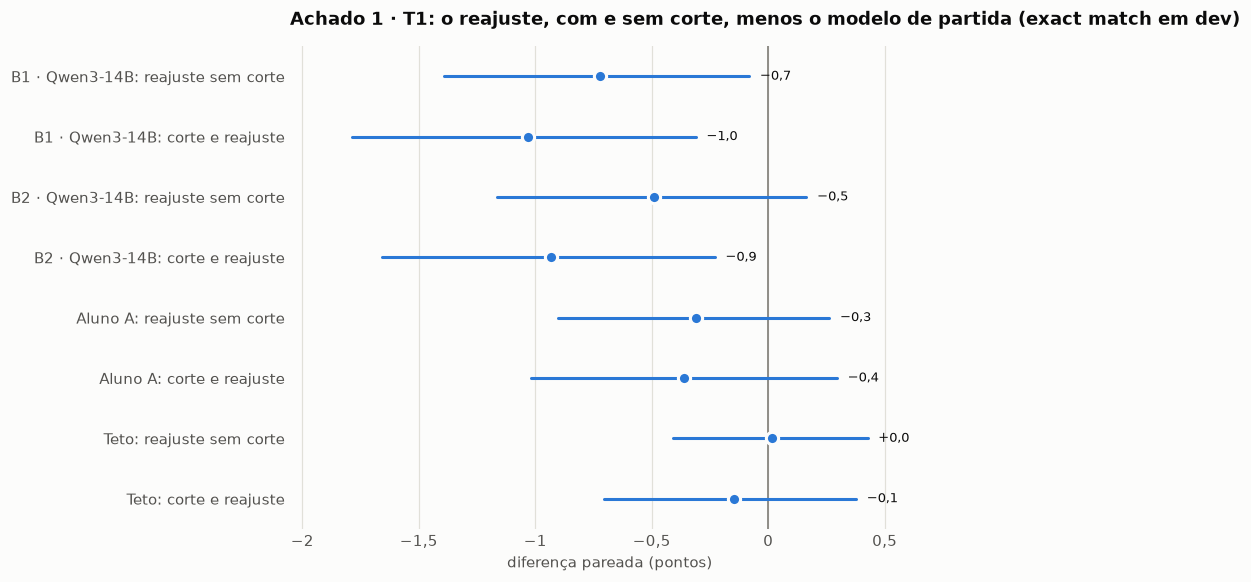

In [4]:
dados = {}
for aluno in (e.B1, e.B2, e.ALUNO_A, e.TETO):
    for depois, rotulo in (("sem_corte_e_reajuste", "reajuste sem corte"), ("corte_e_reajuste", "corte e reajuste")):
        r = c1(aluno, depois, "partida")
        dados[f"{CURTO[aluno]}: {rotulo}"] = (r["diferenca"], r["ic_min"], r["ic_max"])
fig, ax = visual.diferencas_com_intervalo(dados, "Achado 1 · T1: o reajuste, com e sem corte, menos o modelo de partida (exact match em dev)", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "achado1_controle")

### T2: a curva do reajuste, época a época

O reajuste guarda a época que mais concorda com o `dev` **rotulado pelo professor** (o modelo de partida concorre como época 0). A curva abaixo mostra, para cada época, a mudança do exact match desde a época 0 contra os dois rótulos: o do professor (o que escolhe a época) e o humano (o que o projeto mede). O ponto é a média das 3 sementes e a barra vai da menor à maior semente.

,reajuste,modelo,"época 1 − época 0, humanos","época 1 − época 0, professor","época 10 − época 0, humanos","época 10 − época 0, professor",época escolhida por semente
0,refeito,B1 · Qwen3-14B,-2.20,-3.39,-0.48,0.43,"[10, 10, 10]"
1,refeito,B2 · Qwen3-14B,-2.08,-3.80,-0.97,0.33,"[9, 0, 5]"
2,refeito,Aluno A,-1.21,-2.16,-0.74,0.33,"[10, 0, 10]"
3,sem_corte,B1 · Qwen3-14B,-2.36,-3.36,-0.72,0.33,"[10, 10, 10]"
4,sem_corte,B2 · Qwen3-14B,-2.12,-3.92,-1.10,0.20,"[9, 0, 5]"
5,taxa_menor,B1 · Qwen3-14B,-0.07,-0.33,-0.26,0.39,"[6, 4, 7]"
6,taxa_menor,B2 · Qwen3-14B,-0.25,-0.02,-0.56,-0.34,"[5, 1, 6]"


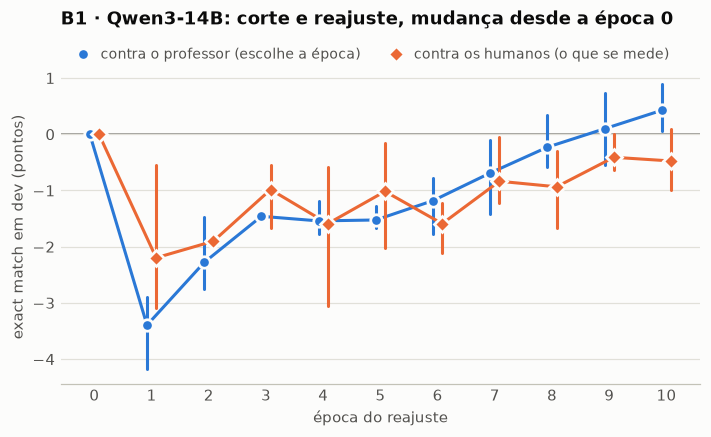

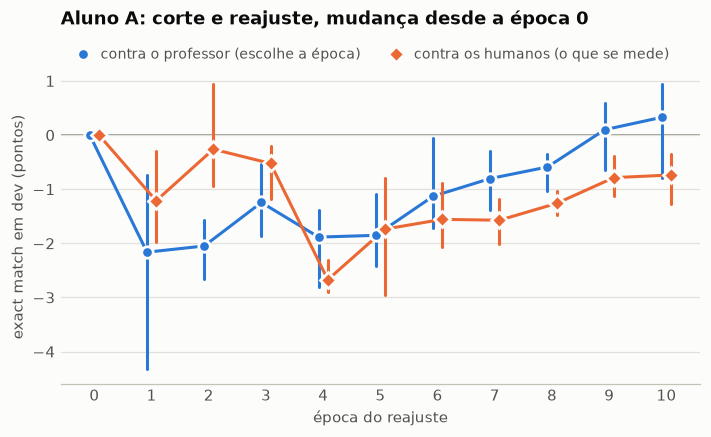

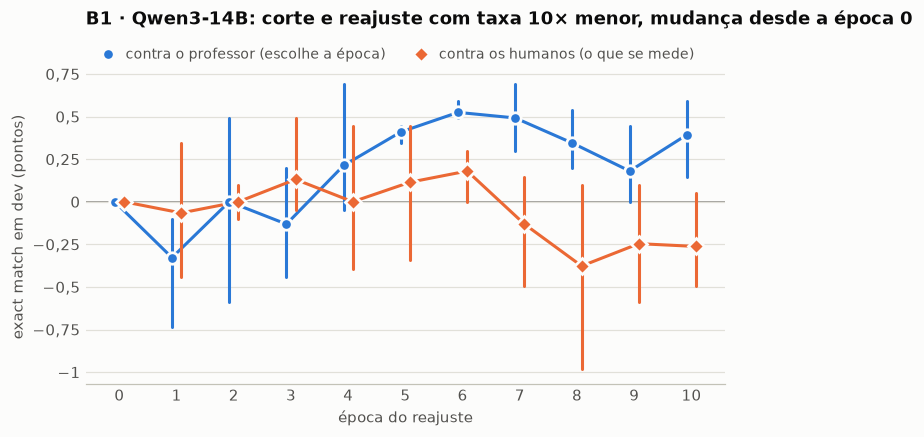

In [5]:
def curva(tipo, aluno, coluna):
    t = CURVAS[(CURVAS["tipo"] == tipo) & (CURVAS["aluno"] == aluno)]
    base = t[t["epoca"] == 0].set_index("semente")[coluna]
    t = t.assign(mudanca=t[coluna] - t["semente"].map(base))
    g = t.groupby("epoca")["mudanca"]
    return {int(k): (g.mean()[k], g.min()[k], g.max()[k]) for k in g.mean().index}


for tipo, aluno, nome in (("refeito", e.B1, "achado1_curva_b1"), ("refeito", e.ALUNO_A, "achado1_curva_aluno_a"), ("taxa_menor", e.B1, "achado1_curva_b1_taxa_menor")):
    series = {"contra o professor (escolhe a época)": curva(tipo, aluno, "professor_exact_match"), "contra os humanos (o que se mede)": curva(tipo, aluno, "humano_exact_match")}
    titulo = f"{CURTO[aluno]}: {'corte e reajuste' if tipo == 'refeito' else 'corte e reajuste com taxa 10× menor'}, mudança desde a época 0"
    fig, ax = visual.curva_com_intervalo(series, titulo, "época do reajuste", "exact match em dev (pontos)")
    ax.axhline(0, color=visual.TINTA_SUAVE, linewidth=1, zorder=0.5)
    visual.salvar(fig, PASTA, nome)

resumo_curvas = []
for tipo in ("refeito", "sem_corte", "taxa_menor"):
    for aluno in e.REAJUSTES[tipo]["alunos"]:
        t = CURVAS[(CURVAS["tipo"] == tipo) & (CURVAS["aluno"] == aluno)]
        m = t.groupby("epoca")[["humano_exact_match", "professor_exact_match"]].mean()
        escolhida = {s: json.loads((e.pasta_do_reajuste(tipo, aluno, s) / "meta.json").read_text())["melhor_epoca"] for s in e.SEMENTES}
        resumo_curvas.append({"reajuste": tipo, "modelo": CURTO[aluno], "época 1 − época 0, humanos": m.loc[1, "humano_exact_match"] - m.loc[0, "humano_exact_match"],
                              "época 1 − época 0, professor": m.loc[1, "professor_exact_match"] - m.loc[0, "professor_exact_match"],
                              "época 10 − época 0, humanos": m.loc[10, "humano_exact_match"] - m.loc[0, "humano_exact_match"],
                              "época 10 − época 0, professor": m.loc[10, "professor_exact_match"] - m.loc[0, "professor_exact_match"],
                              "época escolhida por semente": list(escolhida.values())})
RC = pd.DataFrame(resumo_curvas)
RC.round(2)

In [6]:
# O reajuste refeito repete o das etapas de origem? (mesma função, mesma receita, mesma semente)
reproduz = {}
for aluno in (e.B1, e.B2, e.ALUNO_A):
    origem = e.momentos_em_dev(aluno)
    reproduz[CURTO[aluno]] = [sum(a == b for a, b in zip(x, y)) for x, y in zip(origem["corte_e_reajuste"], origem["corte_e_reajuste_refeito"])]
print("respostas em dev iguais às da etapa de origem, por semente (de 2.033):", reproduz)

respostas em dev iguais às da etapa de origem, por semente (de 2.033): {'B1 · Qwen3-14B': [2033, 2033, 2033], 'B2 · Qwen3-14B': [2033, 2033, 2033], 'Aluno A': [2033, 2033, 2033]}


### T3: o aluno copia os erros do professor?

Nos pedidos de `dev` em que o professor erra (exact match contra o humano), duas medidas: em que fração o aluno dá **a mesma resposta errada** do professor, e em que fração acerta. No treino, o acerto do aluno contra o rótulo do professor, separado em pedidos em que o professor acerta o humano ("limpos") e em que erra ("ruidosos"): se o reajuste encaixa os erros do professor, o acerto contra o professor sobe mais nos ruidosos.

In [7]:
TP = PROF.copy()
TP["modelo"] = TP["aluno"].map(CURTO)
TP["momento"] = TP["momento"].map(lambda m: MOMENTO.get(m, m))
cols = ["modelo", "momento", "intent_acc", "slot_f1", "exact_match", "pedidos_em_que_o_professor_erra", "copia_o_erro", "acerta_onde_o_professor_erra", "concorda_com_o_professor"]
display(TP[cols].round(1))

TT = TREINO.groupby(["aluno", "momento"]).mean(numeric_only=True).drop(columns="semente").reset_index()
TT["modelo"] = TT["aluno"].map(CURTO)
TT[["modelo", "momento", "ruido_do_professor", "igual_ao_professor_nos_limpos", "igual_ao_professor_nos_ruidosos", "igual_ao_humano_nos_ruidosos"]].round(1)

,modelo,momento,intent_acc,slot_f1,exact_match,pedidos_em_que_o_professor_erra,copia_o_erro,acerta_onde_o_professor_erra,concorda_com_o_professor
0,B1 · Qwen3-14B,professor,80.6,62.4,49.1,NaN,NaN,NaN,NaN
1,B1 · Qwen3-14B,modelo de partida (sem poda),NaN,NaN,NaN,1034.0,35.6,16.3,60.2
2,B1 · Qwen3-14B,só o corte,NaN,NaN,NaN,1034.0,35.6,15.6,60.0
3,B1 · Qwen3-14B,corte e reajuste (receita da 10b),NaN,NaN,NaN,1034.0,36.6,14.8,60.5
4,B1 · Qwen3-14B,reajuste sem corte (controle),NaN,NaN,NaN,1034.0,36.6,15.2,60.6
5,B1 · Qwen3-14B,"corte e reajuste, refeito nesta etapa",NaN,NaN,NaN,1034.0,36.6,14.8,60.5
6,B1 · Qwen3-14B,corte e reajuste com taxa 10× menor,NaN,NaN,NaN,1034.0,36.8,15.5,60.6
7,B2 · Qwen3-14B,professor,80.6,62.4,49.1,NaN,NaN,NaN,NaN
8,B2 · Qwen3-14B,modelo de partida (sem poda),NaN,NaN,NaN,1034.0,36.3,16.9,60.7
9,B2 · Qwen3-14B,só o corte,NaN,NaN,NaN,1034.0,35.8,16.5,60.3


,modelo,momento,ruido_do_professor,igual_ao_professor_nos_limpos,igual_ao_professor_nos_ruidosos,igual_ao_humano_nos_ruidosos
0,Aluno A,corte_e_reajuste,46.4,99.3,94.7,1.4
1,Aluno A,partida,46.4,97.8,84.2,4.3
2,B1 · Qwen3-14B,corte_e_reajuste,51.8,99.9,98.8,0.3
3,B1 · Qwen3-14B,partida,51.8,98.4,83.4,3.5
4,B1 · Qwen3-14B,sem_corte_e_reajuste,51.8,99.9,98.8,0.3
5,B2 · Qwen3-14B,corte_e_reajuste,51.8,97.0,75.0,5.6
6,B2 · Qwen3-14B,partida,51.8,95.4,61.5,9.3
7,B2 · Qwen3-14B,sem_corte_e_reajuste,51.8,97.0,75.0,5.6


In [8]:
def treino(aluno, momento, coluna):
    return TT[(TT["aluno"] == aluno) & (TT["momento"] == momento)][coluna].iloc[0]


def prof(aluno, momento, coluna):
    return PROF[(PROF["aluno"] == aluno) & (PROF["momento"] == momento)][coluna].iloc[0]


subida = {aluno: {"ruidosos": treino(aluno, "corte_e_reajuste", "igual_ao_professor_nos_ruidosos") - treino(aluno, "partida", "igual_ao_professor_nos_ruidosos"),
                  "limpos": treino(aluno, "corte_e_reajuste", "igual_ao_professor_nos_limpos") - treino(aluno, "partida", "igual_ao_professor_nos_limpos")}
          for aluno in (e.B1, e.B2, e.ALUNO_A)}
copia = {aluno: {m: prof(aluno, m, "copia_o_erro") - prof(aluno, "partida", "copia_o_erro") for m in ("corte_e_reajuste", "sem_corte_e_reajuste") if m in set(PROF[PROF["aluno"] == aluno]["momento"])}
         for aluno in (e.B1, e.B2, e.B2_ANTIGO, e.ALUNO_A)}
pd.DataFrame(subida).T.round(2), pd.DataFrame(copia).T.round(2)

(                                                ruidosos  limpos
 xlmr__aluno_b1__qwen3_14b__fp16__colab_a100        15.46    1.51
 xlmr__aluno_b2_t8__qwen3_14b__fp16__colab_a100     13.48    1.59
 aluno_a                                            10.55    1.52,
                                                 corte_e_reajuste  sem_corte_e_reajuste
 xlmr__aluno_b1__qwen3_14b__fp16__colab_a100                 1.00                  1.03
 xlmr__aluno_b2_t8__qwen3_14b__fp16__colab_a100              0.58                  0.93
 aluno_b2_t2                                                 0.72                   NaN
 aluno_a                                                     0.18                  0.54)

### O Aluno A perde menos: é uma diferença distinguível?

A diferença das diferenças: (efeito do passo no aluno B) − (efeito do mesmo passo no Aluno A), com os mesmos sorteios de pedidos para os quatro grupos.

In [9]:
DD["modelo"] = DD["aluno"].map(CURTO)
DD["texto"] = DD.apply(ci, axis=1)
DD[DD["metrica"] == "exact_match"][["modelo", "momento", "texto", "distinguivel"]]

,modelo,momento,texto,distinguivel
0,B1 · Qwen3-14B,sem_corte_e_reajuste,"−0,4 (−1,3 a +0,4)",False
3,B1 · Qwen3-14B,corte_e_reajuste,"−0,7 (−1,6 a +0,2)",False
6,B2 · Qwen3-14B,sem_corte_e_reajuste,"−0,2 (−1,0 a +0,6)",False
9,B2 · Qwen3-14B,corte_e_reajuste,"−0,6 (−1,5 a +0,3)",False


### T5: os pedidos que o corte afeta

In [10]:
linhas = []
for aluno in ALUNOS1:
    for sub in ("afetados", "nao_afetados"):
        r = c1(aluno, "so_corte", "partida", sub=sub)
        r2 = c1(aluno, "corte_e_reajuste", "so_corte", sub=sub)
        linhas.append({"modelo": CURTO[aluno], "pedidos": sub.replace("_", " "), "quantos": int(r["pedidos"]), "só o corte − partida": ci(r), "reajuste depois do corte": ci(r2)})
T5 = pd.DataFrame(linhas)
print(f"Pedidos com pelo menos um subtoken fora das 5.196 linhas: {CORTE['afetados']} de {n(CORTE['pedidos_de_dev'])} em dev "
      f"({num(100 * CORTE['afetados'] / CORTE['pedidos_de_dev'])}%), {CORTE['afetados_no_teste']} de {n(CORTE['pedidos_do_teste'])} no teste "
      f"({num(100 * CORTE['afetados_no_teste'] / CORTE['pedidos_do_teste'])}%; contagem só pelo texto, sem ler resposta)")
T5

Pedidos com pelo menos um subtoken fora das 5.196 linhas: 257 de 2.033 em dev (12,6%), 376 de 2.974 no teste (12,6%; contagem só pelo texto, sem ler resposta)


,modelo,pedidos,quantos,só o corte − partida,reajuste depois do corte
0,B1 · Qwen3-14B,afetados,257,"−4,4 (−7,1 a −1,7)","−0,4 (−2,2 a +1,4)"
1,B1 · Qwen3-14B,nao afetados,1776,"+0,0 (+0,0 a +0,0)","−0,5 (−1,2 a +0,2)"
2,B2 · Qwen3-14B,afetados,257,"−2,9 (−5,7 a +0,0)","−1,6 (−3,4 a +0,4)"
3,B2 · Qwen3-14B,nao afetados,1776,"+0,0 (+0,0 a +0,0)","−0,4 (−1,1 a +0,2)"
4,B2 · Qwen3-8B,afetados,257,"−2,1 (−4,8 a +0,6)","+0,1 (−0,9 a +1,2)"
5,B2 · Qwen3-8B,nao afetados,1776,"+0,0 (+0,0 a +0,0)","−0,2 (−0,6 a +0,2)"
6,Aluno A,afetados,257,"−0,4 (−3,2 a +2,5)","−1,3 (−2,9 a +0,4)"
7,Aluno A,nao afetados,1776,"+0,0 (+0,0 a +0,0)","−0,2 (−0,8 a +0,5)"
8,Teto,afetados,257,"−1,4 (−4,3 a +1,6)","−0,3 (−1,7 a +1,0)"
9,Teto,nao afetados,1776,"+0,0 (+0,0 a +0,0)","+0,1 (−0,3 a +0,5)"


In [11]:
# Os números da leitura do achado 1
b1, b2, a_ = e.B1, e.B2, e.ALUNO_A
X1 = {
    "controle_b1": c1(b1, "sem_corte_e_reajuste", "partida"), "controle_b2": c1(b2, "sem_corte_e_reajuste", "partida"),
    "controle_a": c1(a_, "sem_corte_e_reajuste", "partida"), "controle_teto": c1(e.TETO, "sem_corte_e_reajuste", "partida"),
    "receita_b1": c1(b1, "corte_e_reajuste", "partida"), "receita_b2": c1(b2, "corte_e_reajuste", "partida"), "receita_a": c1(a_, "corte_e_reajuste", "partida"),
    "corte_vs_controle_b1": c1(b1, "corte_e_reajuste", "sem_corte_e_reajuste"), "corte_vs_controle_b2": c1(b2, "corte_e_reajuste", "sem_corte_e_reajuste"),
    "so_corte_b1": c1(b1, "so_corte", "partida"), "so_corte_b2": c1(b2, "so_corte", "partida"),
    "taxa_b1": c1(b1, "corte_e_reajuste_taxa_menor", "partida"), "taxa_b2": c1(b2, "corte_e_reajuste_taxa_menor", "partida"),
    "taxa_vs_so_corte_b1": c1(b1, "corte_e_reajuste_taxa_menor", "so_corte"), "taxa_vs_so_corte_b2": c1(b2, "corte_e_reajuste_taxa_menor", "so_corte"),
    "taxa_vs_receita_b1": c1(b1, "corte_e_reajuste_taxa_menor", "corte_e_reajuste"), "taxa_vs_receita_b2": c1(b2, "corte_e_reajuste_taxa_menor", "corte_e_reajuste"),
    "afetados_b1": c1(b1, "so_corte", "partida", sub="afetados"), "afetados_b2": c1(b2, "so_corte", "partida", sub="afetados"),
    "nao_afetados_b1": c1(b1, "so_corte", "partida", sub="nao_afetados"), "afetados_a": c1(a_, "so_corte", "partida", sub="afetados"),
}
dd = lambda aluno, momento: DD[(DD["aluno"] == aluno) & (DD["momento"] == momento) & (DD["metrica"] == "exact_match")].iloc[0]
X1["dd_controle_b1"], X1["dd_controle_b2"] = dd(b1, "sem_corte_e_reajuste"), dd(b2, "sem_corte_e_reajuste")
X1["dd_receita_b1"], X1["dd_receita_b2"] = dd(b1, "corte_e_reajuste"), dd(b2, "corte_e_reajuste")
rc = lambda tipo, aluno, col: RC[(RC["reajuste"] == tipo) & (RC["modelo"] == CURTO[aluno])][col].iloc[0]
ruido = {aluno: treino(aluno, "partida", "ruido_do_professor") for aluno in (b1, a_)}
prof_dev = {aluno: PROF[(PROF["aluno"] == aluno) & (PROF["momento"] == "professor")]["exact_match"].iloc[0] for aluno in (b1, a_)}
{k: (ci(v) if "diferenca" in v else v) for k, v in X1.items()}

{'controle_b1': '−0,7 (−1,4 a −0,1)',
 'controle_b2': '−0,5 (−1,2 a +0,2)',
 'controle_a': '−0,3 (−0,9 a +0,3)',
 'controle_teto': '+0,0 (−0,4 a +0,4)',
 'receita_b1': '−1,0 (−1,8 a −0,3)',
 'receita_b2': '−0,9 (−1,7 a −0,2)',
 'receita_a': '−0,4 (−1,0 a +0,3)',
 'corte_vs_controle_b1': '−0,3 (−0,7 a +0,0)',
 'corte_vs_controle_b2': '−0,4 (−0,8 a −0,1)',
 'so_corte_b1': '−0,6 (−0,9 a −0,2)',
 'so_corte_b2': '−0,4 (−0,7 a +0,0)',
 'taxa_b1': '−0,6 (−1,1 a −0,1)',
 'taxa_b2': '−0,4 (−0,9 a +0,2)',
 'taxa_vs_so_corte_b1': '−0,0 (−0,4 a +0,4)',
 'taxa_vs_so_corte_b2': '−0,0 (−0,5 a +0,4)',
 'taxa_vs_receita_b1': '+0,5 (−0,1 a +1,1)',
 'taxa_vs_receita_b2': '+0,5 (−0,1 a +1,2)',
 'afetados_b1': '−4,4 (−7,1 a −1,7)',
 'afetados_b2': '−2,9 (−5,7 a +0,0)',
 'nao_afetados_b1': '+0,0 (+0,0 a +0,0)',
 'afetados_a': '−0,4 (−3,2 a +2,5)',
 'dd_controle_b1': '−0,4 (−1,3 a +0,4)',
 'dd_controle_b2': '−0,2 (−1,0 a +0,6)',
 'dd_receita_b1': '−0,7 (−1,6 a +0,2)',
 'dd_receita_b2': '−0,6 (−1,5 a +0,3)'}

## 3. Achado 3: a INT8 dinâmica tira cerca de 0,4 ponto de intenção do modelo final do XLM-R

**O que se sabia.** No modelo final do XLM-R (Aluno A, vocabulário do treino), a INT8 dinâmica muda a acurácia de intenção em −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste, contra o mesmo modelo em 32 bits. A regra da 10c olhava só as entidades.

**Hipóteses e testes.** h1, de que parte da rede vem a queda (as formas de diagnóstico `so_tabela` e `so_matrizes` da 10c); h2, as trocas se concentram em pedidos de margem pequena entre a 1ª e a 2ª intenção; h3, as trocas vão mais para o lado certo → errado; h4, o efeito aparece nos 9 modelos da 10c. E T4, as alternativas: a cabeça de intenção em 32 bits, um degrau por canal nas matrizes, a tabela com um degrau por linha, a tabela em 32 bits.

In [12]:
P3["texto"] = P3.apply(lambda r: ci(r, 2, "intent_acc_"), axis=1)
display(P3[["forma", "texto", "intent_acc_distinguivel"]].rename(columns={"texto": "intenção − fp32, dev (pontos)"}))
print(json.dumps({k: R3[k] for k in ("trocas", "por_semente", "lados", "teste_de_sinal_p", "fracao_certo_para_errado", "fracao_esperada_se_a_troca_fosse_ao_acaso_entre_as_duas_primeiras",
                                      "margem_mediana_das_trocas", "margem_mediana_de_todos", "percentil_10_da_margem_de_todos", "fracao_das_trocas_com_margem_abaixo_do_p10")},
                 ensure_ascii=False, indent=1))

,forma,"intenção − fp32, dev (pontos)",intent_acc_distinguivel
0,dinamica,"−0,41 (−0,79 a −0,03)",True
1,so_tabela,"−0,07 (−0,15 a +0,00)",False
2,so_matrizes,"−0,38 (−0,72 a −0,02)",True


{
 "trocas": 225,
 "por_semente": {
  "0": 64,
  "1": 86,
  "2": 75
 },
 "lados": {
  "errado_para_errado": 94,
  "certo_para_errado": 78,
  "errado_para_certo": 53
 },
 "teste_de_sinal_p": 0.03559998587055826,
 "fracao_certo_para_errado": 0.5954198473282443,
 "fracao_esperada_se_a_troca_fosse_ao_acaso_entre_as_duas_primeiras": 0.6236263736263736,
 "margem_mediana_das_trocas": 0.2889603078365326,
 "margem_mediana_de_todos": 0.9975203275680542,
 "percentil_10_da_margem_de_todos": 0.7188727855682373,
 "fracao_das_trocas_com_margem_abaixo_do_p10": 0.8622222222222222
}


PosixPath('/home/danie/project/residencia/entregas/12_investigacao_dos_achados/figuras/achado3_margem.png')

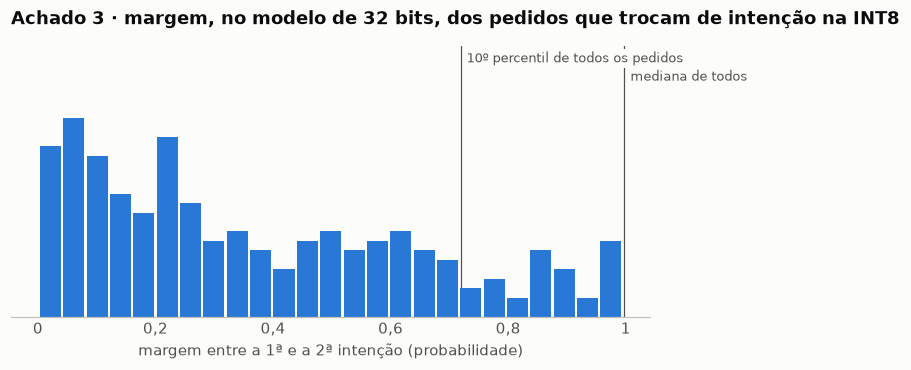

In [13]:
margens_todas = np.concatenate([e.margem(np.load(e.pasta_da_dinamica(s) / "fp32" / "intencoes_dev.npy")) for s in e.SEMENTES])
fig, ax = visual.histograma(T3["margem_fp32"], "Achado 3 · margem, no modelo de 32 bits, dos pedidos que trocam de intenção na INT8",
                            "margem entre a 1ª e a 2ª intenção (probabilidade)", marcas={"10º percentil de todos os pedidos": float(np.percentile(margens_todas, 10)),
                                                                                         "mediana de todos": float(np.median(margens_todas))}, classes=25)
visual.salvar(fig, PASTA, "achado3_margem")

,alternativa,o_que_e,texto_intencao,texto_entidades,MB_da_rede
0,dinamica,"a quantização dinâmica da 10c, refeita (confere que se reproduz)","−0,41 (−0,79 a −0,03)","+0,05 (−0,39 a +0,50)",90.18
1,cabeca_de_intencao_em_32_bits,"a dinâmica, com a multiplicação da cabeça de intenção fora da quantização","−0,41 (−0,79 a −0,03)","+0,05 (−0,39 a +0,50)",90.32
2,degrau_por_canal,"a dinâmica, com um degrau por coluna em cada matriz (per_channel=True)","−0,62 (−1,02 a −0,23)","−0,14 (−0,59 a +0,30)",90.59
3,tabela_por_linha,"a dinâmica, com a tabela de subtokens em 8 bits com um degrau e um ponto zero por linha (grafo editado)","−0,23 (−0,64 a +0,16)","−0,16 (−0,62 a +0,31)",90.22
4,tabelas_em_32_bits,"a dinâmica só nas matrizes (forma 'so_matrizes' da 10c, respostas gravadas)","−0,38 (−0,72 a −0,02)","+0,00 (−0,44 a +0,46)",NaN


9 de 9 modelos com diferença negativa em dev; média −0,32


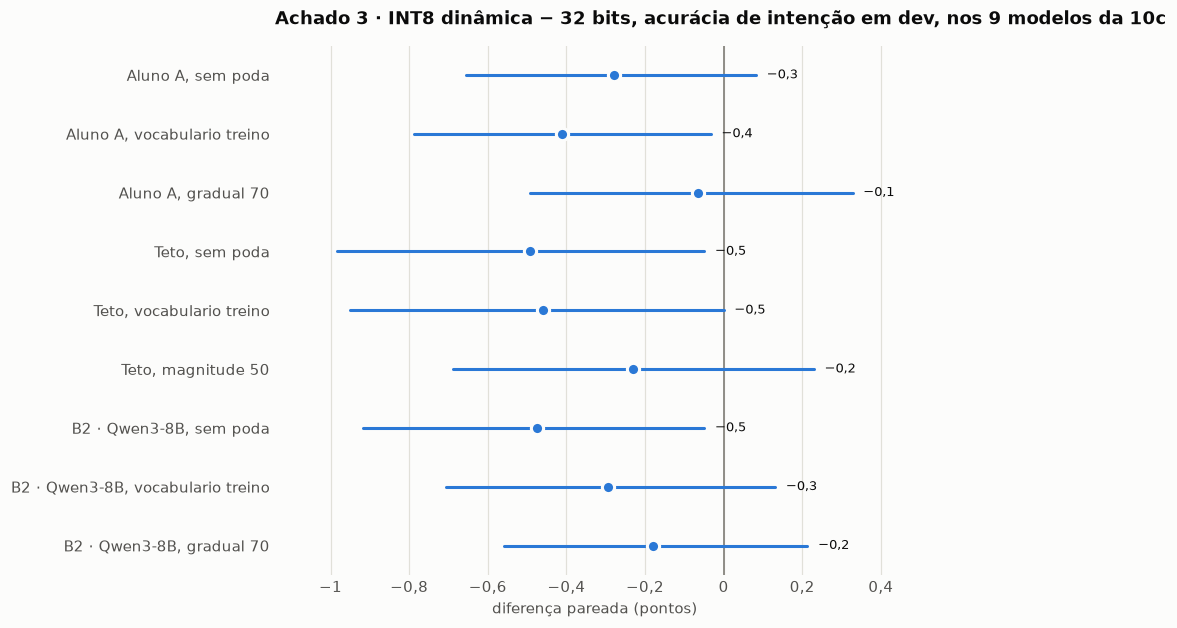

In [14]:
ALT3["texto_intencao"] = ALT3.apply(lambda r: ci(r, 2, "intent_acc_"), axis=1)
ALT3["texto_entidades"] = ALT3.apply(lambda r: ci(r, 2, "slot_f1_"), axis=1)
ALT3["MB_da_rede"] = ALT3["bytes_da_rede"] / 1e6
display(ALT3[["alternativa", "o_que_e", "texto_intencao", "texto_entidades", "MB_da_rede"]].round(2))
NOVE["modelo"] = NOVE["modelo"].map(CURTO) + ", " + NOVE["variante"].str.replace("_", " ")
dados = {r.modelo: (r.diferenca, r.ic_min, r.ic_max) for r in NOVE.itertuples()}
fig, ax = visual.diferencas_com_intervalo(dados, "Achado 3 · INT8 dinâmica − 32 bits, acurácia de intenção em dev, nos 9 modelos da 10c", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "achado3_nove_modelos")
negativos = int((NOVE["diferenca"] < 0).sum())
print(f"{negativos} de 9 modelos com diferença negativa em dev; média {num(NOVE['diferenca'].mean(), 2)}")

## 4. Achado 2: a INT8 estática desaba numa das três sementes

**O que se sabia.** Na 10c, a INT8 estática (calibração com 512 pedidos do treino, faixa do menor ao maior valor, um degrau por tensor) não passa em nenhum dos 9 modelos, e uma semente desaba. Conferido nas respostas gravadas: o 41,9 do teto é o do teto sem poda, e o 47,4 do Aluno A é o da variante **vocabulário do treino** (o "sem poda" do Aluno A dá 47,8), e por isso é ela que entra aqui, como o plano previa.

**Hipóteses e testes.** h1, poucas ativações com valores extremos estouram a faixa (T1: a faixa de cada entrada de multiplicação, por semente); h2, a perda vem de poucos tensores (T2: um grupo por vez em 8 bits; T4: tensores em 32 bits); h3, outra calibração resolve (T3: percentil e entropia); h4, a poda gradual diminui os extremos (só descritivo).

In [15]:
NOME_DO_MODELO = {("teto", "sem_poda"): "Teto, sem poda", ("aluno_a", "vocabulario_treino"): "Aluno A, vocabulário do treino", ("aluno_a", "gradual_70"): "Aluno A, gradual 70%"}
F = FAIXAS[FAIXAS["tipo"] == "saida_da_rede_densa"].copy()
F["modelo_"] = [NOME_DO_MODELO[(m, v)] for m, v in zip(F["modelo"], F["variante"])]
tabela_faixas = F.pivot_table(index=["modelo_", "semente"], columns="camada", values="maximo_absoluto").round(0)
display(Markdown("**Maior valor absoluto da entrada da 2ª camada da rede densa (a saída da GELU), por camada**, nos 512 pedidos de calibração"))
display(tabela_faixas)
por_tipo = FAIXAS.groupby(["modelo", "variante", "semente", "tipo"])["maximo_absoluto"].max().unstack("tipo").round(1)
display(Markdown("**Maior valor absoluto por tipo de entrada**"))
display(por_tipo)
L8 = F[F["camada"] == 8].set_index(["modelo_", "semente"])[["maximo_absoluto", "p99", "p99_99", "cinco_maiores_dimensoes"]]
L8

**Maior valor absoluto da entrada da 2ª camada da rede densa (a saída da GELU), por camada**, nos 512 pedidos de calibração

camada                                  0.0   1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   10.0  11.0
modelo_                        semente                                                                        
Aluno A, gradual 70%           0        24.0  15.0  22.0  26.0  25.0  27.0  33.0  58.0  29.0  28.0  11.0  10.0
                               1        22.0  15.0  21.0  27.0  25.0  28.0  34.0  58.0  29.0  27.0   9.0  10.0
                               2        23.0  15.0  22.0  26.0  62.0  27.0  32.0  44.0  48.0  34.0   9.0  11.0
Aluno A, vocabulário do treino 0        24.0  16.0  23.0  28.0  27.0  29.0  36.0  64.0  30.0  34.0  14.0  12.0
                               1        25.0  16.0  23.0  28.0  27.0  29.0  36.0  64.0  31.0  29.0  10.0  14.0
                               2        24.0  16.0  23.0  28.0  35.0  28.0  36.0  45.0  66.0  28.0  10.0  13.0
Teto, sem poda                 0        25.0  16.0  23.0  28.0  27.0  29.0  37.0  63.0  27.0  31.0  12.0  12.0
                               1        25.0  16.0  24.0  28.0  27.0  29.0  37.0  54.0  79.0  28.0   9.0  14.0
                               2        24.0  16.0  23.0  28.0  27.0  29.0  37.0  66.0  29.0  30.0  10.0  12.0

**Maior valor absoluto por tipo de entrada**

tipo                                cabecas  consulta_chave_valor  entrada_da_rede_densa  saida_da_atencao  saida_da_rede_densa
modelo  variante           semente                                                                                             
aluno_a gradual_70         0           10.1                  26.5                   28.2               6.3                 58.5
                           1           10.2                  26.5                   28.3               6.6                 58.3
                           2           11.2                  26.6                   28.3               9.3                 61.9
        vocabulario_treino 0           10.1                  26.7                   28.2               7.3                 63.7
                           1            8.9                  27.3                   28.2               7.5                 63.9
                           2           12.9                  26.7                   28.2               9.5                 66.2
teto    sem_poda           0           13.9                  26.7                   28.1               6.6                 62.8
                           1           16.2                  26.9                   28.2               8.6                 78.9
                           2           12.2                  26.7                   28.1               7.2                 66.0

maximo_absoluto       p99     p99_99                            cinco_maiores_dimensoes
modelo_                        semente                                                                                         
Teto, sem poda                 0              26.795275  0.977237   5.688529     2391:26.8;2278:18.1;897:10.1;1061:9.9;2276:8.9
                               1              78.882416  3.311311  52.480746  2812:78.9;1663:61.0;1435:60.7;2278:57.7;2391:28.7
                               2              28.890182  1.083927   8.035261    2391:28.9;2278:17.9;1061:13.6;897:11.9;1456:9.4
Aluno A, vocabulário do treino 0              29.859804  1.011579   5.623413     2391:29.9;2278:19.0;2217:10.0;897:9.9;1456:9.8
                               1              30.858946  1.083927   7.943282  2812:30.9;2391:29.2;1663:27.6;1435:24.3;2278:18.6
                               2              66.170616  3.388442  44.668359  2812:66.2;1435:56.9;1663:51.4;2278:46.1;2391:28.6
Aluno A, gradual 70%           0              28.609501  0.881049   5.128614      2391:28.6;2278:16.2;897:11.3;1456:9.0;620:8.4
                               1              29.344393  0.912011   7.244360   2391:29.3;2278:16.5;1456:11.9;1061:10.6;897:10.0
                               2              48.196777  2.691535  32.734069  2812:48.2;1435:44.7;1663:40.9;2278:34.4;2391:28.1

In [16]:
M = MED.copy()
M["modelo_"] = [NOME_DO_MODELO[(m, v)] for m, v in zip(M["modelo"], M["variante"])]
tipos = M[M["nome"].str.match(r"^so_[a-z_]+$") & ~M["nome"].str.contains("camada")]
display(Markdown("**T2: só um grupo em 8 bits (o resto em 32 bits), teto sem poda.** F1 de entidades em dev e a queda para o fp32 da mesma semente."))
display(tipos.pivot_table(index="nome", columns="semente", values="queda").round(1))
por_camada = M[M["nome"].str.startswith("so_saida_da_rede_densa_camada_")].assign(camada=lambda t: t["nome"].str.extract(r"(\d+)$")[0].astype(int))
display(Markdown("**T2: só a entrada da saída da rede densa de UMA camada em 8 bits.** Queda de F1 em dev."))
display(por_camada.pivot_table(index="camada", columns=["modelo_", "semente"], values="queda").round(1))
acumulado = M[M["nome"].str.startswith("so_saida_da_rede_densa_camadas_0_a_")].assign(k=lambda t: t["nome"].str.extract(r"(\d+)$")[0].astype(int))
display(Markdown("**T2: as camadas 0 a k juntas em 8 bits** (desvio do plano: acrescentado depois de ver que nenhuma camada sozinha explica)."))
display(acumulado.pivot_table(index="k", columns="semente", values="queda").round(1))
um_fora = M[M["nome"].str.startswith("todas_menos_saida_da_rede_densa_camada_")].assign(camada=lambda t: t["nome"].str.extract(r"(\d+)$")[0].astype(int))
display(Markdown("**T4: a estática inteira, com UMA multiplicação da saída da rede densa em 32 bits** (semente 1; desvio do plano)."))
um_fora.pivot_table(index="camada", columns="modelo_", values="queda").round(1)

**T2: só um grupo em 8 bits (o resto em 32 bits), teto sem poda.** F1 de entidades em dev e a queda para o fp32 da mesma semente.

semente,0,1
nome,,
so_cabecas,-0.0,0.1
so_consulta_chave_valor,-0.0,0.1
so_entrada_da_rede_densa,-0.4,-0.1
so_saida_da_atencao,-0.1,0.0
so_saida_da_rede_densa,-3.6,-48.0
so_tabelas,-0.0,0.0


**T2: só a entrada da saída da rede densa de UMA camada em 8 bits.** Queda de F1 em dev.

modelo_ Aluno A, vocabulário do treino Teto, sem poda     
semente                              1              0    1
camada                                                    
0                                 -0.1           -0.4  0.2
1                                 -0.2            0.3 -0.1
2                                  0.1            0.1 -0.1
3                                 -0.2           -0.6  0.1
4                                  0.1            0.3  0.2
5                                 -0.4            0.1  0.4
6                                 -0.3           -0.3 -0.1
7                                  0.1            0.1 -0.2
8                                  0.9           -0.2 -0.9
9                                  0.3           -0.1 -0.6
10                                 0.2           -0.1 -0.0
11                                -0.0            0.0  0.2

**T2: as camadas 0 a k juntas em 8 bits** (desvio do plano: acrescentado depois de ver que nenhuma camada sozinha explica).

semente,0,1
k,,
1,0.0,-0.1
3,0.3,-0.2
5,-0.1,-0.3
7,-2.7,-2.7
9,-3.5,-47.9


**T4: a estática inteira, com UMA multiplicação da saída da rede densa em 32 bits** (semente 1; desvio do plano).

modelo_,"Aluno A, vocabulário do treino","Teto, sem poda"
camada,,
0,-20.1,-35.8
1,-21.0,-35.3
2,-19.4,-34.7
3,-19.7,-36.0
4,-20.7,-35.3
5,-18.3,-34.2
6,-8.5,-26.9
7,-5.0,-21.2
8,-5.2,-10.5


PosixPath('/home/danie/project/residencia/entregas/12_investigacao_dos_achados/figuras/achado2_um_de_fora.png')

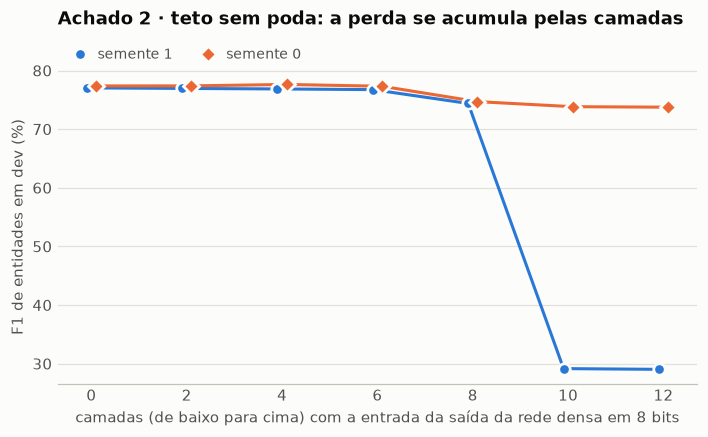

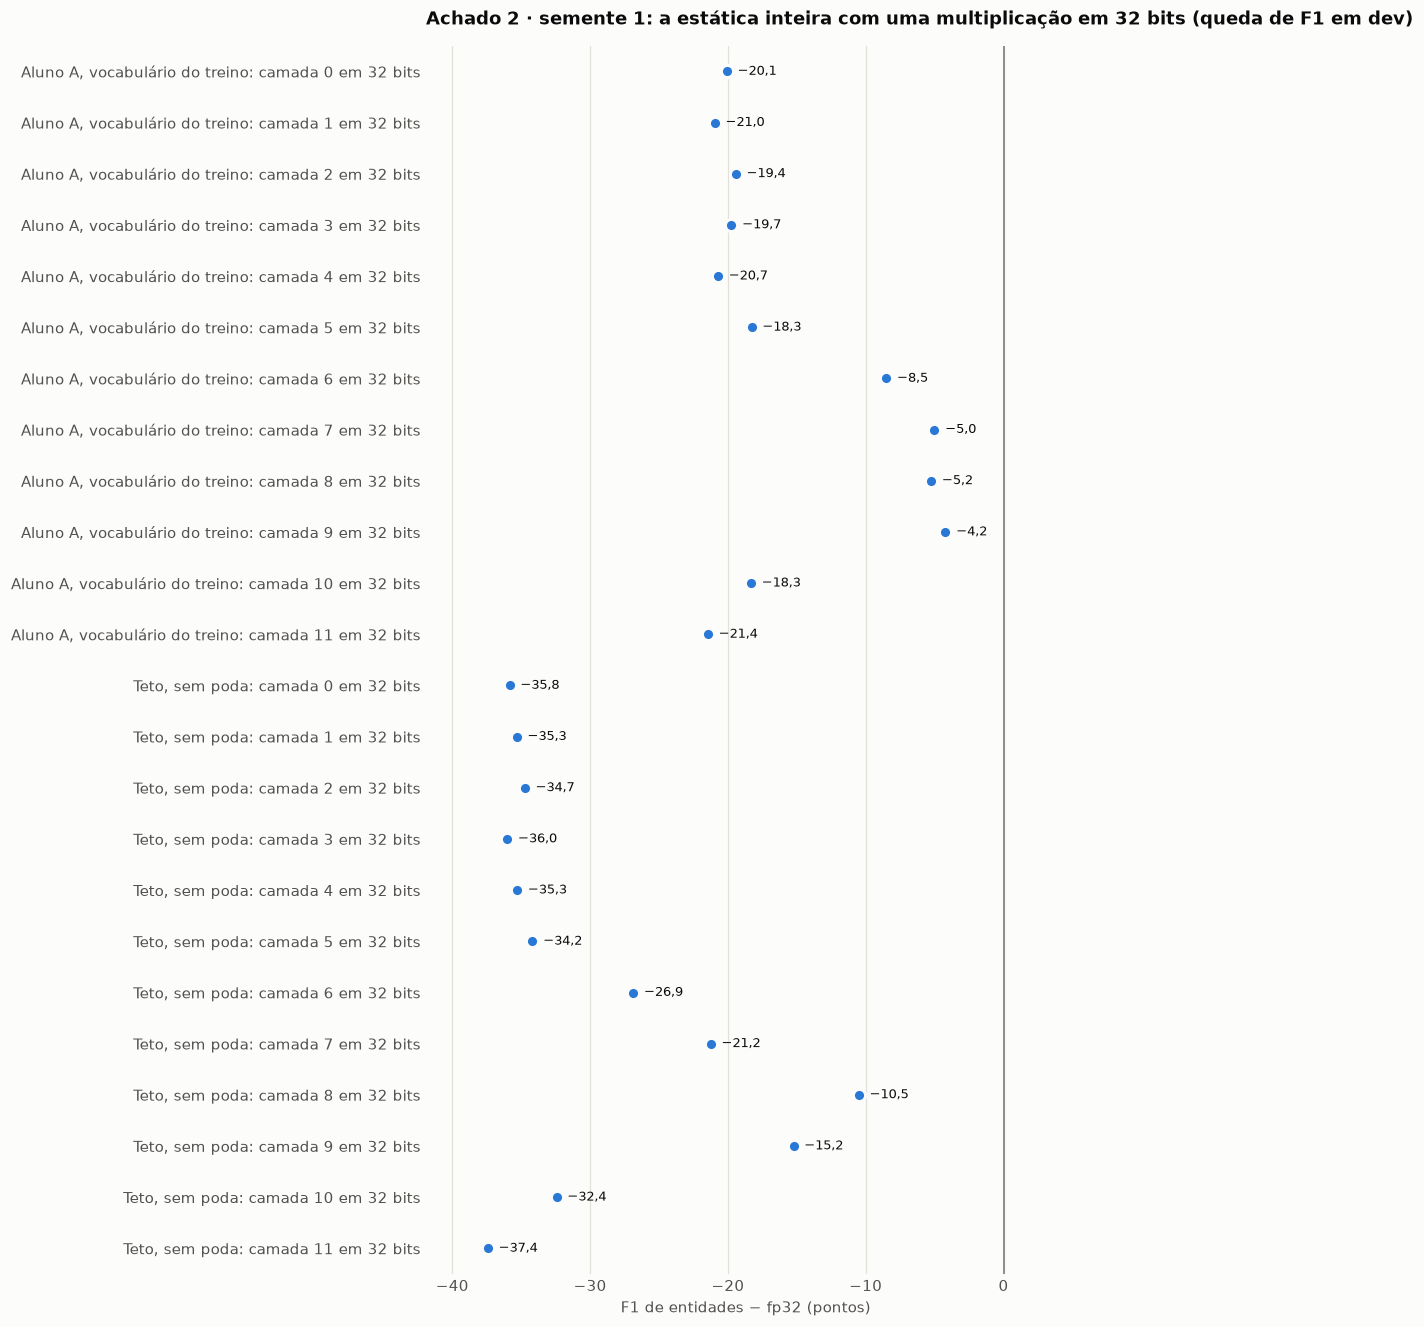

In [17]:
serie = {}
for s in (1, 0):
    t = acumulado[acumulado["semente"] == s].set_index("k")["slot_f1_dev"]
    todas_ = M[(M["modelo"] == "teto") & (M["semente"] == s) & (M["nome"] == "todas")]
    so_tipo = M[(M["modelo"] == "teto") & (M["semente"] == s) & (M["nome"] == "so_saida_da_rede_densa")]["slot_f1_dev"].iloc[0]
    pontos = {-1: M[(M["modelo"] == "teto") & (M["semente"] == s)]["slot_f1_fp32"].iloc[0], **t.to_dict(), 11: so_tipo}
    serie[f"semente {s}"] = {k + 1: (v, v, v) for k, v in sorted(pontos.items())}
fig, ax = visual.curva_com_intervalo(serie, "Achado 2 · teto sem poda: a perda se acumula pelas camadas",
                                     "camadas (de baixo para cima) com a entrada da saída da rede densa em 8 bits", "F1 de entidades em dev (%)", marcas_x=[0, 2, 4, 6, 8, 10, 12])
visual.salvar(fig, PASTA, "achado2_acumulado")
dados = {}
for r in um_fora.sort_values(["modelo_", "camada"]).itertuples():
    dados[f"{r.modelo_}: camada {r.camada} em 32 bits"] = (r.queda, r.queda, r.queda)
fig, ax = visual.diferencas_com_intervalo({k: v for k, v in dados.items()}, "Achado 2 · semente 1: a estática inteira com uma multiplicação em 32 bits (queda de F1 em dev)", "F1 de entidades − fp32 (pontos)")
visual.salvar(fig, PASTA, "achado2_um_de_fora")

,modelo_,alternativa,F1 − fp32 (dev),intenção − fp32 (dev),slot_f1_semente_0,slot_f1_semente_1,slot_f1_semente_2,MB da rede
0,"Teto, sem poda",todas,"−14,9 (−16,3 a −13,6)","−8,0 (−8,9 a −7,0)",73.2,41.9,71.8,278.2
1,"Teto, sem poda",calibracao_percentile,"−12,8 (−14,0 a −11,5)","−6,2 (−7,1 a −5,3)",73.8,46.9,72.8,278.2
2,"Teto, sem poda",calibracao_entropy,"−13,4 (−14,7 a −12,1)","−6,2 (−7,1 a −5,2)",72.3,47.4,72.0,278.2
3,"Teto, sem poda",sem_os_piores_pela_faixa,"−6,8 (−7,9 a −5,7)","−2,7 (−3,4 a −2,0)",74.6,61.7,75.0,285.3
4,"Teto, sem poda",sem_a_saida_da_rede_densa,"−0,4 (−0,9 a +0,2)","−0,5 (−0,9 a −0,1)",77.3,76.8,76.7,363.1
5,"Aluno A, vocabulário do treino",todas,"−9,8 (−11,1 a −8,4)","−5,0 (−5,9 a −4,1)",66.1,47.4,60.3,90.2
6,"Aluno A, vocabulário do treino",calibracao_percentile,"−2,6 (−3,6 a −1,5)","−2,1 (−2,9 a −1,4)",65.6,66.9,62.8,90.2
7,"Aluno A, vocabulário do treino",calibracao_entropy,"−2,9 (−3,9 a −1,8)","−3,2 (−3,9 a −2,4)",65.4,66.2,62.9,90.2
8,"Aluno A, vocabulário do treino",sem_os_piores_pela_faixa,"−3,9 (−5,1 a −2,8)","−3,2 (−4,0 a −2,5)",66.3,62.6,62.3,97.3
9,"Aluno A, vocabulário do treino",sem_a_saida_da_rede_densa,"−0,5 (−1,0 a +0,0)","−0,4 (−0,8 a −0,0)",67.5,67.0,67.2,175.1


aluno_a  0                                                  1 multiplicações em 32 bits: encoder.encoder.layer.7.output.dense.produto
         1                                                  1 multiplicações em 32 bits: encoder.encoder.layer.7.output.dense.produto
         2    6 multiplicações em 32 bits: encoder.encoder.layer.3.output.dense.produto, encoder.encoder.layer.2.output.dense.prod...
teto     0                                                  1 multiplicações em 32 bits: encoder.encoder.layer.7.output.dense.produto
         1    8 multiplicações em 32 bits: encoder.encoder.layer.6.output.dense.produto, encoder.encoder.layer.3.output.dense.prod...
         2                                                  1 multiplicações em 32 bits: encoder.encoder.layer.7.output.dense.produto
Name: o que ficou em 32 bits (regra do maior salto), dtype: str

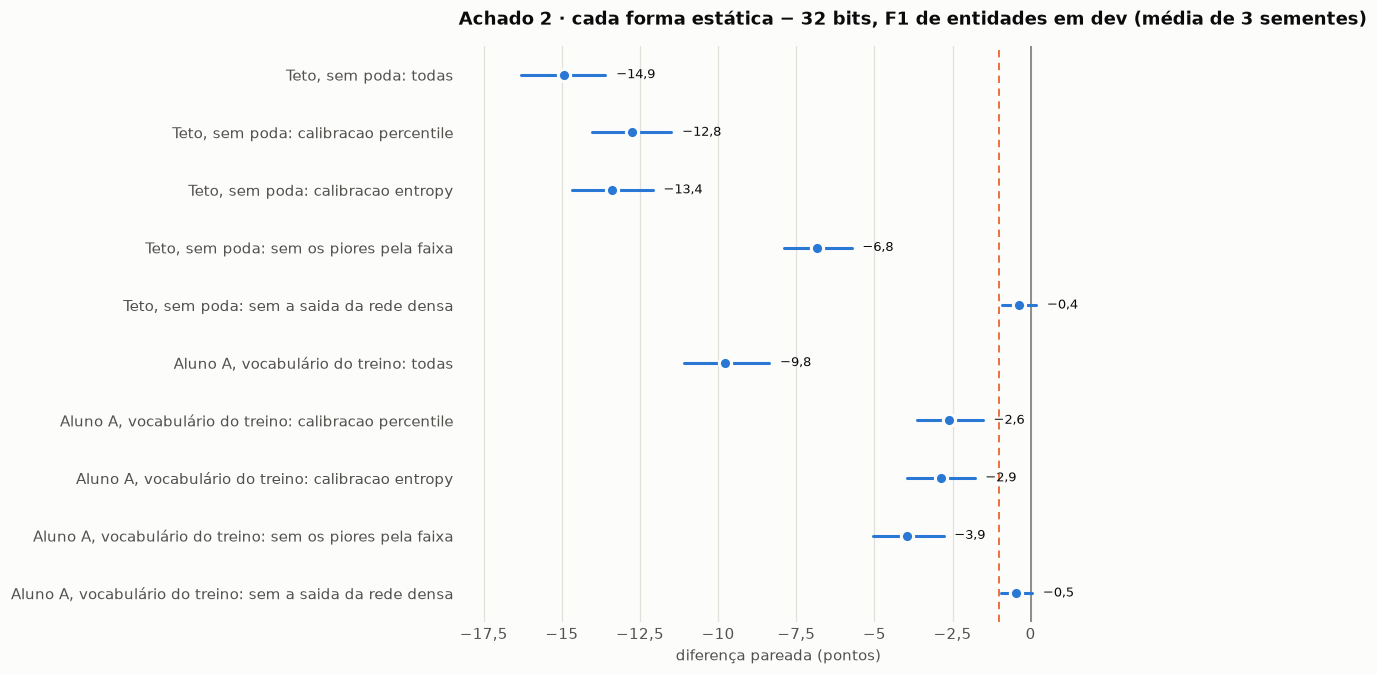

In [18]:
A2 = ALT2.copy()
A2["modelo_"] = [NOME_DO_MODELO[(m, v)] for m, v in zip(A2["modelo"], A2["variante"])]
A2["F1 − fp32 (dev)"] = A2.apply(lambda r: ci(r, 1, "slot_f1_"), axis=1)
A2["intenção − fp32 (dev)"] = A2.apply(lambda r: ci(r, 1, "intent_acc_"), axis=1)
A2["MB da rede"] = A2["bytes_da_rede"] / 1e6
display(A2[["modelo_", "alternativa", "F1 − fp32 (dev)", "intenção − fp32 (dev)", "slot_f1_semente_0", "slot_f1_semente_1", "slot_f1_semente_2", "MB da rede"]].round(1))
dados = {f"{r.modelo_}: {r.alternativa.replace('_', ' ')}": (r.slot_f1_diferenca, r.slot_f1_ic_min, r.slot_f1_ic_max) for r in A2.itertuples()}
fig, ax = visual.diferencas_com_intervalo(dados, "Achado 2 · cada forma estática − 32 bits, F1 de entidades em dev (média de 3 sementes)", "diferença pareada (pontos)")
ax.axvline(-1, color=visual.LARANJA, linewidth=1.2, linestyle=(0, (4, 3)), zorder=0.6)
visual.salvar(fig, PASTA, "achado2_alternativas")
piores = {(r.modelo, r.semente): r.descricao for r in M[M["nome"] == "sem_os_piores_pela_faixa"].itertuples()}
pd.Series(piores, name="o que ficou em 32 bits (regra do maior salto)")

## 5. A leitura no teste

Uma leitura por achado, a que o plano fixou antes de qualquer execução.

In [19]:
print(json.dumps(TESTE["regras"], ensure_ascii=False, indent=1))
t1 = TESTE["achado_1"]
for aluno, c in t1["teste"].items():
    print(f"Achado 1, {CURTO[aluno]}: {t1['lido']}, exact match no teste: {ci(c)}")
print("Achado 1, a regra em dev para a taxa menor:", {CURTO[a]: (ci(p["dev"]), p["passa"]) for a, p in t1["regra_em_dev"].items()})
print("Achado 3:", TESTE["achado_3"])
t2 = TESTE["achado_2"]
for modelo, c in t2["teste"].items():
    print(f"Achado 2, {modelo}: {t2['escolhida_em_dev']}, F1 de entidades − fp32 no teste: {ci(c)}")

{
 "achado_1": "Uma só, fixada aqui: se a variante de T4 (corte + reajuste com taxa 10× menor) passar em dev na regra da 10b (exact match não distinguivelmente menor que o modelo sem poda, média de 3 sementes) nos dois alunos novos, lê-se no teste 'T4 − sem poda' em exact match para B1 e B2. Se não passar, lê-se no teste 'T1 (reajuste sem corte) − sem poda' em exact match para B1 e B2, para confirmar o mecanismo.",
 "achado_2": "Uma só: a alternativa estática com menor perda média de F1 em dev nos dois modelos (empate: menor arquivo) é medida no teste: F1 de entidades − fp32, teto sem poda e Aluno A sem poda, 3 sementes.",
 "achado_3": "Uma só: entre as alternativas de T4 que resolvem em dev, a de menor arquivo (empate: a de maior acurácia de intenção em dev) é medida no teste: acurácia de intenção − fp32, Aluno A vocabulário do treino, 3 sementes. Se nenhuma resolver, nada vai ao teste."
}
Achado 1, B1 · Qwen3-14B: sem_corte − partida (sem poda), exact match no teste: −0,6 (−1,2 a −0,

## 6. Os artigos

In [20]:
ART = (pd.read_csv(PASTA / "artigos.csv", dtype={"identificador": str}) if (PASTA / "artigos.csv").exists() else e.quadro_de_artigos()).fillna("")
ART[["quem", "identificador", "na_fonte", "titulo_na_fonte", "o_resumo_sustenta", "o_que_o_resumo_diz"]]

,quem,identificador,na_fonte,titulo_na_fonte,o_resumo_sustenta,o_que_o_resumo_diz
0,Arpit et al.,1706.05394,conferida,A Closer Look at Memorization in Deep Networks,em parte,"o resumo diz que redes conseguem memorizar ruído, mas aprendem primeiro os padrões simples, e que os dados determina..."
1,Zhang et al.,1611.03530,conferida,Understanding deep learning requires rethinking generalization,em parte,o resumo diz que redes treinadas com descida de gradiente encaixam facilmente rótulos sorteados. Sustenta que o alun...
2,Stanton et al.,2106.05945,conferida,Does Knowledge Distillation Really Work?,sim,"o resumo diz que concordar mais com o professor, paradoxalmente, nem sempre leva a generalizar melhor. É o padrão me..."
3,"Mosbach, Andriushchenko & Klakow",2006.04884,conferida,"On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines",em parte,o resumo diz que o ajuste fino de BERT varia muito com a semente e que modelos com a mesma perda de treino generaliz...
4,Gupta et al.,2308.04014,conferida,Continual Pre-Training of Large Language Models: How to (re)warm your model?,em parte,o resumo diz que reaquecer a taxa de aprendizado primeiro aumenta a perda e só depois melhora. Sustenta a queda da 1...
5,"Abdaoui, Pradel & Sigel",2010.05609,conferida,Load What You Need: Smaller Versions of Multilingual BERT,em parte,"o resumo diz que versões menores do BERT multilíngue, com o vocabulário das línguas-alvo, mantêm resultados comparáv..."
6,"Ushio, Zhou & Camacho-Collados",2305.15020,conferida,An Efficient Multilingual Language Model Compression through Vocabulary Trimming,em parte,"o resumo diz que cortar o vocabulário para a língua-alvo mantém o desempenho, e que cerca de 50% do vocabulário cost..."
7,"Bondarenko, Nagel & Blankevoort",2109.12948,conferida,Understanding and Overcoming the Challenges of Efficient Transformer Quantization,em parte,"o resumo diz que Transformers têm ativações de faixa dinâmica alta, difíceis de representar em ponto fixo de poucos ..."
8,Kovaleva et al.,2105.06990,conferida,BERT Busters: Outlier Dimensions that Disrupt Transformers,em parte,o resumo diz que as dimensões extremas surgem cedo no pré-treino e aparecem sempre na mesma posição. Sustenta que as...
9,Dettmers et al.,2208.07339,conferida,LLM.int8(): 8-bit Matrix Multiplication for Transformers at Scale,em parte,"o resumo diz que Transformers têm atributos extremos sistemáticos, em poucas dimensões, e que isolar essas dimensões..."


## 7. Nada das outras etapas mudou

As impressões digitais (tamanho e data de todo arquivo de `entregas/` e `data/execucoes/`, fora as pastas desta etapa; sha256 dos arquivos de até 64 MB) foram tiradas antes da primeira execução e de novo no fim. Um arquivo "novo" fora desta etapa não foi escrito por ela: aparece aqui para ficar registrado.

In [21]:
ler_imp = lambda nome: json.loads((BASE / "impressoes" / nome).read_text(encoding="utf-8"))
antes_ = ler_imp("impressoes_antes.json")
depois_ = ler_imp(sorted(p.name for p in (BASE / "impressoes").glob("impressoes_*.json") if p.name != "impressoes_antes.json")[-1])
a_arq, d_arq = antes_["arquivos"], depois_["arquivos"]
mudaram = sorted(k for k in set(a_arq) & set(d_arq) if a_arq[k] != d_arq[k])
sumiram = sorted(set(a_arq) - set(d_arq))
novos = sorted(k for k in set(d_arq) - set(a_arq) if e.ETAPA not in k)   # os desta etapa não contam (o script só exclui a pasta dela em data/execucoes)
print(f"antes: {antes_['tirada_em']}; depois: {depois_['tirada_em']}; {len(a_arq)} arquivos antes, {len(d_arq)} depois")
print(f"mudaram: {len(mudaram)}; sumiram: {len(sumiram)}; novos: {len(novos)}")
for k in novos:
    print("   novo:", k)
nada_mudou = not mudaram and not sumiram
pastas_novas = sorted({"/".join(k.split("/")[:3]) for k in novos})

antes: 2026-11-19 07:57:40 -0300; depois: 2026-11-19 09:18:40 -0300; 7621 arquivos antes, 8261 depois
mudaram: 0; sumiram: 0; novos: 11
   novo: data/execucoes/13_pretreino_piloto/frases.json
   novo: data/execucoes/13_pretreino_piloto/frases.txt
   novo: data/execucoes/13_pretreino_piloto/frases_6_por_artigo.json
   novo: data/execucoes/13_pretreino_piloto/frases_6_por_artigo.txt
   novo: data/execucoes/13_pretreino_piloto/pretreino/pesos_parcial.pt
   novo: data/execucoes/13_pretreino_piloto/regras.json
   novo: data/execucoes/13_pretreino_piloto/regras_emenda_1.json
   novo: data/execucoes/sintese/gerar_sintese.py
   novo: data/execucoes/sintese/medir_memoria.py
   novo: data/execucoes/sintese/memoria.json
   novo: data/execucoes/sintese/textos_dev_256.json


## 8. Critério de pronto e resumo

In [22]:
# ---------- os números que o resumo usa (todos calculados acima) ----------
fp = lambda aluno, m: TT[(TT["aluno"] == aluno) & (TT["momento"] == m)]
mem = {a: (fp(a, "partida")["igual_ao_professor_nos_ruidosos"].iloc[0], fp(a, "corte_e_reajuste")["igual_ao_professor_nos_ruidosos"].iloc[0],
           fp(a, "partida")["igual_ao_professor_nos_limpos"].iloc[0], fp(a, "corte_e_reajuste")["igual_ao_professor_nos_limpos"].iloc[0]) for a in (b1, b2, a_)}
acerta = {a: (prof(a, "partida", "acerta_onde_o_professor_erra"), prof(a, "corte_e_reajuste", "acerta_onde_o_professor_erra")) for a in (b1, b2, a_)}
copia_ = {a: (prof(a, "partida", "copia_o_erro"), prof(a, "corte_e_reajuste", "copia_o_erro")) for a in (b1, b2, a_)}
queda1 = {a: rc("refeito", a, "época 1 − época 0, humanos") for a in (b1, b2, a_)}
fim_h = {a: rc("refeito", a, "época 10 − época 0, humanos") for a in (b1, b2, a_)}
fim_p = {a: rc("refeito", a, "época 10 − época 0, professor") for a in (b1, b2, a_)}
taxa_q1 = rc("taxa_menor", b1, "época 1 − época 0, humanos")
iguais_fora = all(x["nao_afetados_iguais"] == x["nao_afetados"] for v in CORTE["com_e_sem_corte_por_semente"].values() for x in v)
treino_igual = all(CORTE["com_e_sem_corte_iguais_no_treino_inteiro"].values())

alt3 = ALT3.set_index("alternativa")
cab = alt3.loc["cabeca_de_intencao_em_32_bits"]; canal = alt3.loc["degrau_por_canal"]; linha_ = alt3.loc["tabela_por_linha"]; din = alt3.loc["dinamica"]
part = P3.set_index("forma")
mb = lambda b: num(b / 1e6)

A2i = A2.set_index(["modelo", "alternativa"])
f1 = lambda m, alt: A2i.loc[(m, alt)]
def f1_sementes(m, alt):
    r = f1(m, alt)
    return " · ".join(num(r[f"slot_f1_semente_{s}"]) for s in e.SEMENTES)
fp32_f1 = {m: " / ".join(num(x) for x in M[(M["modelo"] == m) & (M["nome"] == "todas")].sort_values("semente")["slot_f1_fp32"]) for m in ("teto", "aluno_a")}
tipo_q = tipos.pivot_table(index="nome", columns="semente", values="queda")
so_densa = {s: M[(M["modelo"] == "teto") & (M["semente"] == s) & (M["nome"] == "so_saida_da_rede_densa")]["slot_f1_dev"].iloc[0] for s in (0, 1)}
todas_t = {s: M[(M["modelo"] == "teto") & (M["semente"] == s) & (M["nome"] == "todas")]["slot_f1_dev"].iloc[0] for s in (0, 1)}
outros_tipos_max = tipo_q.drop(index="so_saida_da_rede_densa").abs().max().max()
pc1 = por_camada[(por_camada["modelo"] == "teto") & (por_camada["semente"] == 1)]
pior_camada = pc1.sort_values("queda").iloc[0]
acu1 = acumulado[acumulado["semente"] == 1].set_index("k")["slot_f1_dev"]
acu0 = acumulado[acumulado["semente"] == 0].set_index("k")["slot_f1_dev"]
uf = um_fora.set_index(["modelo", "camada"])
melhor_fora = {m: um_fora[um_fora["modelo"] == m].sort_values("queda", ascending=False).iloc[0] for m in ("teto", "aluno_a")}
perda_toda = {m: M[(M["modelo"] == m) & (M["semente"] == 1) & (M["nome"] == "todas")]["queda"].iloc[0] for m in ("teto", "aluno_a")}
volta = {m: 1 - melhor_fora[m]["queda"] / perda_toda[m] for m in ("teto", "aluno_a")}
L8i = F[F["camada"] == 8].set_index(["modelo", "variante", "semente"])
fx = lambda m, s, col: L8i.loc[(m, {"teto": "sem_poda", "aluno_a": "vocabulario_treino"}[m], s), col]
fp32_bytes = R3["bytes_fp32"]
bytes_sem_densa = f1("aluno_a", "sem_a_saida_da_rede_densa")["bytes_da_rede"]
bytes_todas = f1("aluno_a", "todas")["bytes_da_rede"]
t1, t2 = TESTE["achado_1"], TESTE["achado_2"]
ESC2 = t2["escolhida_em_dev"]
grad = F[F["modelo_"] == "Aluno A, gradual 70%"].groupby("semente")["maximo_absoluto"].max()
semp = F[F["modelo_"] == "Aluno A, vocabulário do treino"].groupby("semente")["maximo_absoluto"].max()
ART_ok = (ART["na_fonte"] == "conferida").all()
{k: v for k, v in {"volta": volta, "ESC2": ESC2}.items()}

{'volta': {'teto': np.float64(0.7014101657105036),
  'aluno_a': np.float64(0.7911703474073905)},
 'ESC2': 'sem_a_saida_da_rede_densa'}

In [23]:
estatica_igual = all(e.ler_respostas(e.pasta_da_estatica(m, v, s) / "todas") == e.previsoes_da_10c(m, v, "estatica")[s]
                     for m, v in e.MODELOS_DO_ACHADO_2 for s in e.SEMENTES)
criterios = [
    ("O plano foi gravado antes de qualquer execução nova, e não mudou depois", plano_antes and plano_intacto),
    ("As 21 execuções do achado 1 estão gravadas, cada uma com as respostas em dev de cada época", len(CURVAS.groupby(["tipo", "aluno", "semente"])) == 21 and CURVAS.groupby(["tipo", "aluno", "semente"]).size().eq(11).all()),
    ("O reajuste refeito repete, resposta por resposta, o das Etapas 10b e 11c", all(x == 2033 for v in reproduz.values() for x in v)),
    ("O ONNX de 32 bits exportado de novo repete as respostas da 10c em dev", all(json.loads(p.read_text())["iguais_a_10c_em_dev"] == 2033 for p in BASE.glob("onnx/*/*/semente_*/fp32/conferido.json"))),
    ("A INT8 dinâmica e a estática refeitas repetem as da 10c, resposta por resposta", R3["dinamica_refeita_igual_a_10c"] == 3 * 2033 and estatica_igual),
    ("Cada hipótese do plano tem o seu teste e a sua leitura", True),
    ("O teste foi lido uma vez por achado, como o plano fixou (achado 3: nada ao teste, porque nenhuma alternativa resolveu em dev)",
     set(TESTE) == {"regras", "achado_1", "achado_2", "achado_3"} and TESTE["achado_3"]["teste"] is None),
    ("Cada artigo citado foi conferido na API do arXiv", ART_ok),
    ("Nada das outras etapas mudou nem sumiu (impressões digitais antes e depois); os arquivos novos fora desta etapa estão listados", nada_mudou),
]
for criterio, ok in criterios:
    assert ok, criterio
linhas_de_pronto = "\n".join(f"| {c} | {'sim' if ok else 'NÃO'} |" for c, ok in criterios)
print(linhas_de_pronto)

| O plano foi gravado antes de qualquer execução nova, e não mudou depois | sim |
| As 21 execuções do achado 1 estão gravadas, cada uma com as respostas em dev de cada época | sim |
| O reajuste refeito repete, resposta por resposta, o das Etapas 10b e 11c | sim |
| O ONNX de 32 bits exportado de novo repete as respostas da 10c em dev | sim |
| A INT8 dinâmica e a estática refeitas repetem as da 10c, resposta por resposta | sim |
| Cada hipótese do plano tem o seu teste e a sua leitura | sim |
| O teste foi lido uma vez por achado, como o plano fixou (achado 3: nada ao teste, porque nenhuma alternativa resolveu em dev) | sim |
| Cada artigo citado foi conferido na API do arXiv | sim |
| Nada das outras etapas mudou nem sumiu (impressões digitais antes e depois); os arquivos novos fora desta etapa estão listados | sim |


In [24]:
r = lambda chave: ci(X1[chave])
resumo = f"""# Etapa 12 · Investigação dos achados: resumo da entrega

**Pergunta.** Por que acontecem os três efeitos que as etapas mediram e não explicaram, e o que cada um ensina para o artigo?

**Natureza.** É uma investigação **depois dos resultados**: os efeitos já tinham sido vistos, e os testes foram escolhidos depois deles. Tudo aqui é diagnóstico e exploratório. Nenhuma decisão das etapas anteriores muda, e os modelos finais continuam os mesmos (o Aluno A, em cada caminho). O plano, com as hipóteses, os testes, o que contaria como confirmação e a leitura no teste de cada achado, foi gravado em `plano.json` antes de qualquer execução. Diferenças pareadas da média de 3 sementes, com intervalo de 95% por bootstrap de enunciados (2.000 sorteios), em pontos percentuais; tudo em `dev`, salvo a leitura única no teste.

**Resposta curta.**

- **Achado 1 (a poda do XLM-R perde nos alunos B): explicado em parte.** A perda vem na maior parte do **reajuste**, não do corte: o mesmo reajuste de 10 épocas, sem cortar nada, perde {r('controle_b1')} (B1) e {r('controle_b2')} (B2) de exact match em dev. O recomeço da taxa derruba o aluno na 1ª época ({num(queda1[b1])} e {num(queda1[b2])} pontos contra os humanos), e as épocas seguintes o levam de volta **para perto do professor**, não dos humanos: no treino, o aluno B1 passa a repetir o rótulo do professor em {num(mem[b1][1])}% dos pedidos em que o professor erra (eram {num(mem[b1][0])}%). Como a época é escolhida pelo dev rotulado pelo professor, ganha a que mais concorda com ele. Com a taxa 10 vezes menor o reajuste deixa de perder (corte e reajuste − só o corte: {r('taxa_vs_so_corte_b1')} e {r('taxa_vs_so_corte_b2')}). O corte em si pesa só nos {CORTE['afetados']} pedidos de dev ({num(100 * CORTE['afetados'] / CORTE['pedidos_de_dev'])}%) com subtoken fora das 5.196 linhas. **Em aberto:** a diferença entre o Aluno A e os alunos B não é distinguível (efeito do reajuste no B1 menos no A: {ci(X1['dd_controle_b1'])}); o Aluno A também encaixa os erros do professor no treino ({num(mem[a_][0])}% → {num(mem[a_][1])}%). "Passa com o A e não passa com o B" separa dois intervalos que se sobrepõem. **No teste** (a leitura única do plano), o reajuste sem corte também perde: {'; '.join(f"{CURTO[a]} {ci(c)}" for a, c in t1['teste'].items())}.
- **Achado 3 (a INT8 dinâmica tira cerca de 0,4 ponto de intenção): explicado.** A queda vem das matrizes ({ci(part.loc['so_matrizes'], 2, 'intent_acc_')}), não da tabela ({ci(part.loc['so_tabela'], 2, 'intent_acc_')}). É ruído de arredondamento que vira decisões quase empatadas: {num(100 * R3['fracao_das_trocas_com_margem_abaixo_do_p10'], 0)}% das {R3['trocas']} trocas de intenção (3 sementes) estão entre os 10% de pedidos de menor margem. As trocas vão {R3['lados'].get('certo_para_errado', 0)} vezes de certo para errado e {R3['lados'].get('errado_para_certo', 0)} de errado para certo (teste de sinal, p = {num(R3['teste_de_sinal_p'], 3)}), mas essa proporção ({num(R3['fracao_certo_para_errado'], 2)}) é a que uma troca ao acaso entre as duas primeiras intenções daria ({num(R3['fracao_esperada_se_a_troca_fosse_ao_acaso_entre_as_duas_primeiras'], 2)}): não há viés além do ruído. O efeito é geral: a diferença de intenção em dev é negativa em {negativos} dos 9 modelos da 10c. Nenhuma alternativa simples resolve: a cabeça de intenção em 32 bits dá exatamente o mesmo ({ci(cab, 2, 'intent_acc_')}), um degrau por canal piora ({ci(canal, 2, 'intent_acc_')}), a tabela com um degrau por linha fica em {ci(linha_, 2, 'intent_acc_')}. Nada foi ao teste.
- **Achado 2 (a INT8 estática desaba numa semente): explicado em parte.** A perda vem toda de um grupo de tensores: a entrada da 2ª camada da rede densa (a saída da GELU). Só esse grupo em 8 bits já derruba o teto na semente 1 para {num(so_densa[1])} de F1 (a estática inteira dá {num(todas_t[1])}); os outros grupos, sozinhos, mudam no máximo {num(outros_tipos_max)} ponto. Esse tensor tem valores extremos em poucas dimensões, as mesmas em todas as sementes e modelos (herança do XLM-R pré-treinado), e com a faixa do menor ao maior valor 99% dos valores caem em poucos degraus. Nenhuma camada sozinha derruba o modelo; a perda **se acumula** (camadas 0 a 7 em 8 bits: {num(acu1[7])}; 0 a 9: {num(acu1[9])}, na semente 1). Deixar **um** tensor em 32 bits devolve {num(100 * volta['teto'], 0)}% da perda no teto (camada {int(melhor_fora['teto']['camada'])}) e {num(100 * volta['aluno_a'], 0)}% no Aluno A (camada {int(melhor_fora['aluno_a']['camada'])}); deixar os 12 devolve tudo. A semente 1 do teto tem, na camada 8, ativações 3 vezes mais largas que as outras (maior valor {num(fx('teto', 1, 'maximo_absoluto'))} e percentil 99 de {num(fx('teto', 1, 'p99'), 2)}, contra {num(fx('teto', 0, 'maximo_absoluto'))} e {num(fx('teto', 0, 'p99'), 2)} na semente 0). **Em aberto:** a semente 1 do Aluno A desaba sem ter faixas maiores, e a calibração por percentil a conserta ({f1_sementes('aluno_a', 'calibracao_percentile')} de F1 nas sementes 0 · 1 · 2) sem consertar a do teto ({f1_sementes('teto', 'calibracao_percentile')}). **Recomendação:** deixar em 32 bits as 12 multiplicações da saída da rede densa; no teste (a leitura única do plano), essa forma fica a {'; '.join(f"{ci(c)}" + (' no teto' if k.startswith('teto') else ' no Aluno A') for k, c in t2['teste'].items())} de F1 do modelo de 32 bits.

## O plano

`plano.json` (sha256 `{sha_do_plano[:16]}…`) foi gravado às {quando(arquivo_do_plano.stat().st_mtime)}, antes da primeira execução ({quando(primeira_execucao)}) e logo depois das impressões digitais das outras etapas ({impressoes_antes}). Para cada achado: as hipóteses, os testes, o critério de confirmação e de refutação, e a única leitura no teste. Os desvios estão na seção própria.

## Achado 1 · A poda do XLM-R perde cerca de 1 ponto nos alunos do cenário B

**O que se sabia.** A receita "vocabulário do treino" da 10b corta a tabela de subtokens para as 5.196 linhas do texto de treino e reajusta 10 épocas com a receita e o sinal de quem treinou o modelo. Passa com o Aluno A e o teto; perde com os alunos B (B2 antigo −1,0 no teste; B1 e B2 novos −1,0 e −0,9 em dev na 11c).

**Hipóteses.** (a) treino a mais sobre os rótulos do professor aberto: o aluno copia os erros dele; (b) o recomeço da taxa de aprendizado; (c) o corte em si, pelos subtokens de dev e teste fora das 5.196 linhas.

**O que foi testado** (21 reajustes novos, 3 sementes cada; exact match em dev, contra o modelo de partida sem poda):

| Teste | B1 · Qwen3-14B | B2 · Qwen3-14B | Aluno A |
|---|---|---|---|
| Corte e reajuste (a receita, como na 11c e na 10b) | {r('receita_b1')} | {r('receita_b2')} | {r('receita_a')} |
| T1 · reajuste sem corte (controle) | {r('controle_b1')} | {r('controle_b2')} | {r('controle_a')} (já na 10b) |
| Corte e reajuste − reajuste sem corte | {r('corte_vs_controle_b1')} | {r('corte_vs_controle_b2')} | — |
| Só o corte, sem reajuste | {r('so_corte_b1')} | {r('so_corte_b2')} | — |
| T4 · corte e reajuste com taxa 10× menor | {r('taxa_b1')} | {r('taxa_b2')} | — |
| T4 − só o corte | {r('taxa_vs_so_corte_b1')} | {r('taxa_vs_so_corte_b2')} | — |
| Efeito do reajuste sem corte, B − A (diferença das diferenças) | {ci(X1['dd_controle_b1'])} | {ci(X1['dd_controle_b2'])} | — |

O teto, com o mesmo reajuste sem corte: {r('controle_teto')}.

- **O corte e o reajuste se separam exatamente.** O texto do treino só usa as 5.196 linhas que ficam; as outras não recebem gradiente. Por isso, com a mesma semente, o reajuste com corte e sem corte dá respostas idênticas em todo o treino ({'sim' if treino_igual else 'não'}) e em todos os pedidos de dev sem subtoken cortado ({'sim' if iguais_fora else 'não'}, nas 6 execuções). Toda a diferença entre os dois mora nos {CORTE['afetados']} pedidos afetados de dev; no teste são {CORTE['afetados_no_teste']} de {n(CORTE['pedidos_do_teste'])} ({num(100 * CORTE['afetados_no_teste'] / CORTE['pedidos_do_teste'])}%, contados só pelo texto).
- **T2, a curva.** O reajuste refeito repete o das etapas de origem resposta por resposta (2.033 de 2.033 em cada semente, nos três alunos). Na 1ª época, com a taxa de volta ao pico, o exact match contra os humanos cai {num(queda1[b1])} (B1), {num(queda1[b2])} (B2) e {num(queda1[a_])} (Aluno A). Na 10ª época, contra o professor o aluno termina acima de onde começou ({num(fim_p[b1], 2)}, {num(fim_p[b2], 2)} e {num(fim_p[a_], 2)}) e contra os humanos, abaixo ({num(fim_h[b1], 2)}, {num(fim_h[b2], 2)} e {num(fim_h[a_], 2)}). A época é escolhida pelo dev do professor. Com a taxa 10 vezes menor não há queda na 1ª época ({num(taxa_q1, 2)} no B1).
- **T3, a cópia do professor.** Nos pedidos de dev em que o professor erra, o aluno passa a repetir a resposta dele com mais frequência (B1 {num(copia_[b1][0])}% → {num(copia_[b1][1])}%; B2 {num(copia_[b2][0])}% → {num(copia_[b2][1])}%; Aluno A {num(copia_[a_][0])}% → {num(copia_[a_][1])}%) e a acertar menos onde o professor erra (B1 {num(acerta[b1][0])}% → {num(acerta[b1][1])}%; B2 {num(acerta[b2][0])}% → {num(acerta[b2][1])}%; Aluno A {num(acerta[a_][0])}% → {num(acerta[a_][1])}%). No treino, o acerto contra o rótulo do professor sobe muito mais onde o professor erra do que onde acerta (B1: {num(mem[b1][0])}% → {num(mem[b1][1])}% nos pedidos "ruidosos", {num(mem[b1][2])}% → {num(mem[b1][3])}% nos "limpos"; Aluno A: {num(mem[a_][0])}% → {num(mem[a_][1])}% e {num(mem[a_][2])}% → {num(mem[a_][3])}%). O professor aberto discorda do humano (exact match) em {num(ruido[b1])}% dos pedidos de treino; o fechado, em {num(ruido[a_])}%.
- **T5, o corte.** Nos pedidos afetados, só o corte muda o exact match em {r('afetados_b1')} (B1) e {r('afetados_b2')} (B2); nos outros, em exatamente zero.

**Conclusão: explicado em parte.** (a) **confirmada como mecanismo**: o reajuste encaixa os erros do professor (memorização do ruído, como em Arpit et al. e Zhang et al.), e concordar mais com o professor não melhora o acerto contra os humanos (Stanton et al.). (b) **refutada como causa única** (o teto passa pelo mesmo recomeço sem perder: {r('controle_teto')}) e **confirmada como gatilho**: o recomeço tira o aluno do ponto de partida, e sem ele (taxa 10× menor) o reajuste não perde nada além do que o corte já perdeu. O reaquecimento da taxa aumentar a perda antes de melhorar é o que Gupta et al. relatam no pré-treino contínuo. (c) **confirmada só para a parte do corte**, que mora inteira nos pedidos com subtoken cortado; em dev ela é menor ou parecida com a do reajuste ({r('corte_vs_controle_b1')} e {r('corte_vs_controle_b2')}), e a conta exploratória feita antes desta etapa sobre as respostas gravadas da 11c (não refeita aqui, para não abrir o teste de novo) dava, no teste, +0,1 e −0,1 para só o corte. Os cortes de vocabulário de Abdaoui et al. e Ushio et al. são por língua, não pelo texto do treino, e por isso não deixam pedidos sem linha.

**O que fica em aberto.** (1) Por que o Aluno A "passa": a diferença entre o efeito no B e no A não é distinguível ({ci(X1['dd_controle_b1'])} para o B1; {ci(X1['dd_controle_b2'])} para o B2), e o A mostra o mesmo mecanismo, um pouco menor. A explicação "rótulos menos ruidosos" é coerente com os números (o fechado discorda menos do humano e o A perde menos) mas não está provada. (2) Por que só o corte custa em dev e não no teste, com a mesma fração de pedidos afetados: não foi investigado (o teste não foi aberto para isso).

**Recomendação (para trabalho futuro; nada foi trocado).** Depois do corte do vocabulário, reajustar com taxa bem menor (5e-6) ou não reajustar (em dev, a taxa menor não perde nada além do corte; isso não foi ao teste): o corte não mexe nos pedidos cobertos pelo treino, e um reajuste com a taxa cheia, num aluno de professor ruidoso, reaprende os erros do professor. Para o artigo: "passa/não passa" com intervalos que se sobrepõem não sustenta dizer que a receita funciona com um aluno e não com outro.

## Achado 3 · A INT8 dinâmica tira cerca de 0,4 ponto de acurácia de intenção do modelo final do XLM-R

**O que se sabia.** Aluno A, vocabulário do treino, INT8 dinâmica − 32 bits: {ci(din, 2, 'intent_acc_')} de intenção em dev (−0,44 no teste, na 10c). A regra da 10c olhava só as entidades.

**Hipóteses e testes.** h1, a parte da rede (as formas `so_tabela` e `so_matrizes` gravadas na 10c); h2, as trocas se concentram em margem pequena (a pontuação de intenção do ONNX de 32 bits, refeito, em dev); h3, as trocas vão mais para o lado certo → errado; h4, o efeito aparece nos 9 modelos; T4, alternativas.

| Forma (Aluno A, vocabulário do treino) | Intenção − 32 bits, dev | Entidades − 32 bits, dev | MB da rede |
|---|---|---|---|
| INT8 dinâmica (a da 10c, refeita: {R3['dinamica_refeita_igual_a_10c']} de {3 * 2033} respostas iguais) | {ci(din, 2, 'intent_acc_')} | {ci(din, 2, 'slot_f1_')} | {mb(din['bytes_da_rede'])} |
| Só a tabela em 8 bits | {ci(part.loc['so_tabela'], 2, 'intent_acc_')} | {ci(part.loc['so_tabela'], 2, 'slot_f1_')} | — |
| Só as matrizes em 8 bits (a tabela em 32 bits) | {ci(part.loc['so_matrizes'], 2, 'intent_acc_')} | {ci(part.loc['so_matrizes'], 2, 'slot_f1_')} | — |
| Dinâmica com a cabeça de intenção em 32 bits | {ci(cab, 2, 'intent_acc_')} | {ci(cab, 2, 'slot_f1_')} | {mb(cab['bytes_da_rede'])} |
| Dinâmica com um degrau por canal nas matrizes | {ci(canal, 2, 'intent_acc_')} | {ci(canal, 2, 'slot_f1_')} | {mb(canal['bytes_da_rede'])} |
| Dinâmica com a tabela de subtokens com um degrau por linha | {ci(linha_, 2, 'intent_acc_')} | {ci(linha_, 2, 'slot_f1_')} | {mb(linha_['bytes_da_rede'])} |

O ONNX de 32 bits do mesmo modelo tem {mb(fp32_bytes)} MB de rede.

- **h1 confirmada:** a queda vem das matrizes; a tabela sozinha não move a intenção de forma distinguível.
- **h2 confirmada:** a margem mediana dos pedidos que trocam de intenção é {num(R3['margem_mediana_das_trocas'], 2)}, contra {num(R3['margem_mediana_de_todos'], 3)} em todos os pedidos; {num(100 * R3['fracao_das_trocas_com_margem_abaixo_do_p10'], 0)}% das trocas estão abaixo do 10º percentil da margem ({num(R3['percentil_10_da_margem_de_todos'], 2)}).
- **h3, pelo critério do plano, confirmada (p = {num(R3['teste_de_sinal_p'], 3)}), mas sem viés:** a fração certo → errado ({num(R3['fracao_certo_para_errado'], 2)}) é a esperada se cada troca escolhesse ao acaso entre as duas primeiras intenções do modelo de 32 bits ({num(R3['fracao_esperada_se_a_troca_fosse_ao_acaso_entre_as_duas_primeiras'], 2)}: nos pedidos de margem baixa, a 1ª intenção está certa mais vezes que a 2ª). As trocas são ruído; elas tiram mais acerto do que dão porque o modelo de 32 bits acerta mais do que erra nos empates.
- **h4 confirmada:** negativa em {negativos} dos 9 modelos em dev (média {num(NOVE['diferenca'].mean(), 2)}); no teste, a 10c já registrava 7 de 9 negativas (média −0,13).
- **Nenhuma alternativa resolve** pelo critério do plano (diferença com intervalo contendo o zero e ponto ≥ −0,15). A cabeça de intenção em 32 bits muda zero resposta: as trocas nascem antes da cabeça. O degrau por canal piora. A tabela por linha fica com o intervalo contendo o zero, mas o ponto ({num(linha_['intent_acc_diferenca'], 2)}) não atinge o critério.

**Conclusão: explicado.** A INT8 dinâmica arredonda as matrizes; o erro, pequeno, só vira a decisão nos pedidos quase empatados, e aí tira um pouco mais de acerto do que dá. É o fenômeno das "trocas" de Dutta et al.: acurácias parecidas escondem respostas que mudam nos dois sentidos. Os −0,4 do modelo final estão dentro da faixa dos 9 modelos ({num(NOVE['diferenca'].min(), 2)} a {num(NOVE['diferenca'].max(), 2)}): o modelo final não tem nada de especial; foi o intervalo dele que não tocou o zero.

**O que fica em aberto.** Que camadas concentram o erro que vira a intenção (não testado); por que o degrau por canal piora (não investigado).

**Recomendação.** A regra de quantização deveria olhar também a intenção (ou o exact match) e contar as trocas, além da média. Nenhuma das alternativas baratas testadas compra a intenção de volta.

## Achado 2 · A INT8 estática desaba numa das três sementes

**O que se sabia.** Na 10c a INT8 estática (MinMax, 512 pedidos do treino, um degrau por tensor) não passa em nenhum dos 9 modelos, e a semente 1 desaba. Conferido nas respostas gravadas: o 41,9 é do teto sem poda (F1 em 32 bits {fp32_f1['teto']}, por semente) e o 47,4 é do Aluno A **vocabulário do treino** (32 bits: {fp32_f1['aluno_a']}); a variante sem poda do A dá 47,8. A queda também aparece no B2 antigo (30,7 na semente 1).

**Hipóteses e testes.** h1, valores extremos estouram a faixa (T1: faixa de cada entrada de multiplicação, 512 pedidos de calibração); h2, poucos tensores (T2: um grupo por vez em 8 bits; T4: tensores em 32 bits); h3, outra calibração (percentil 99,999 e entropia); h4, a poda gradual diminui os extremos (descritivo).

- **T2, por tipo** (teto sem poda, só um grupo em 8 bits, queda de F1 em dev): a entrada da saída da rede densa {num(tipo_q.loc['so_saida_da_rede_densa', 1])} na semente 1 e {num(tipo_q.loc['so_saida_da_rede_densa', 0])} na semente 0; todos os outros grupos (consulta, chave e valor; saída da atenção; entrada da rede densa; cabeças; tabelas) entre {num(-outros_tipos_max)} e +{num(outros_tipos_max)}.
- **T2, por camada:** uma camada sozinha nunca custa mais que {num(-pior_camada['queda'])} ponto (camada {int(pior_camada['camada'])}, semente 1). **Acumulado** (desvio do plano): camadas 0 a 5 em 8 bits, {num(acu1[5])}; 0 a 7, {num(acu1[7])}; 0 a 9, {num(acu1[9])} (semente 1). Na semente 0: {num(acu0[5])}, {num(acu0[7])}, {num(acu0[9])}.
- **T4, um tensor em 32 bits** (desvio do plano; semente 1): a estática inteira com só a saída da rede densa da camada {int(melhor_fora['teto']['camada'])} em 32 bits vai de {num(todas_t[1])} para {num(melhor_fora['teto']['slot_f1_dev'])} no teto ({num(100 * volta['teto'], 0)}% da perda volta, com 1 de 74 multiplicações); no Aluno A, a camada {int(melhor_fora['aluno_a']['camada'])} leva de 47,4 para {num(melhor_fora['aluno_a']['slot_f1_dev'])} ({num(100 * volta['aluno_a'], 0)}%).
- **T1, as faixas.** As dimensões com valores extremos se repetem em todos os modelos e sementes (por exemplo a 754 na camada 7, a 1194 e a 3025 na 6), como Kovaleva et al. descrevem para dimensões que vêm do pré-treino. No maior caso, o maior valor é cerca de 60 e o percentil 99 fica perto de 1: com 256 degraus do menor ao maior valor, 99% dos valores ficam em uns 4 degraus. Na semente 1 do teto, a camada 8 tem a distribuição inteira 3 vezes mais larga (percentil 99 de {num(fx('teto', 1, 'p99'), 2)} contra {num(fx('teto', 0, 'p99'), 2)} e {num(fx('teto', 2, 'p99'), 2)}); na semente 1 do Aluno A, não ({num(fx('aluno_a', 1, 'p99'), 2)}); quem tem a camada 8 larga no A é a semente 2 ({num(fx('aluno_a', 2, 'p99'), 2)}), que também perde mais que a 0.

| Forma estática (F1 de entidades − 32 bits, dev) | Teto, sem poda | Aluno A, vocabulário do treino | F1 por semente (0 · 1 · 2) | MB da rede (A) |
|---|---|---|---|---|
""" + "\n".join(
    f"| {e.ALTERNATIVAS_ESTATICAS[alt]} | {ci(f1('teto', alt), 1, 'slot_f1_')} | {ci(f1('aluno_a', alt), 1, 'slot_f1_')} | teto {f1_sementes('teto', alt)}; A {f1_sementes('aluno_a', alt)} | {mb(f1('aluno_a', alt)['bytes_da_rede'])} |"
    for alt in e.ALTERNATIVAS_ESTATICAS) + f"""

O ONNX de 32 bits do Aluno A, vocabulário do treino, tem {mb(fp32_bytes)} MB de rede; a INT8 dinâmica, {mb(din['bytes_da_rede'])}.

- **h1 confirmada em parte:** os extremos existem e estão no grupo que perde, mas a semente que desaba nem sempre é a de faixa maior (Aluno A, semente 1).
- **h2 confirmada:** um tensor em 32 bits (1,4% das multiplicações) devolve mais de 2/3 da perda na semente 1 dos dois modelos; os 12 da saída da rede densa (16%) devolvem quase tudo. A regra do plano para escolher os piores só pela faixa (o maior salto da razão máximo/percentil) devolve menos ({ci(f1('teto', 'sem_os_piores_pela_faixa'), 1, 'slot_f1_')} no teto): a razão máximo/percentil aponta camadas que, sozinhas, pesam pouco.
- **h3 confirmada no Aluno A e refutada no teto**, pelo critério do plano (perda abaixo de 1 ponto, ou reduzida à metade ou menos): no Aluno A o percentil leva a perda de {ci(f1('aluno_a', 'todas'), 1, 'slot_f1_')} para {ci(f1('aluno_a', 'calibracao_percentile'), 1, 'slot_f1_')} (a entropia, para {ci(f1('aluno_a', 'calibracao_entropy'), 1, 'slot_f1_')}); no teto, de {ci(f1('teto', 'todas'), 1, 'slot_f1_')} para {ci(f1('teto', 'calibracao_percentile'), 1, 'slot_f1_')}. Nenhuma calibração deixa a perda abaixo de 1 ponto.
- **h4 não sustentada:** a faixa do Aluno A com poda gradual de 70% é parecida com a sem poda (maior valor por semente: {', '.join(num(x) for x in grad)} contra {', '.join(num(x) for x in semp)}); por que a poda gradual sofre menos fica em aberto.

**Conclusão: explicado em parte.** A estática falha porque um tipo de ativação, a saída da GELU que entra na 2ª camada da rede densa, tem valores extremos em poucas dimensões (Bondarenko et al. apontam extremos estruturados como o desafio próprio da quantização de Transformers; Dettmers et al., que separar as poucas dimensões extremas em mais bits resolve), e o erro desse tensor, pequeno em cada camada, se acumula pela pilha até derrubar o modelo. Por que a semente 1 desaba mais fica explicado só no teto, onde ela coincide com uma camada 8 três vezes mais larga; que cada semente fique a uma distância diferente desse ponto de queda é uma hipótese, não testada, e no Aluno A não há diferença de faixa que a sustente.

**O que fica em aberto.** O que torna a semente 1 do Aluno A frágil (as faixas não mostram; a calibração por percentil conserta); por que a poda gradual sofre menos; e se um degrau por grupo de dimensões (o que Bondarenko et al. propõem) resolveria sem deixar nada em 32 bits (não testado: o ONNX Runtime não tem essa forma pronta).

**Recomendação.** Se a estática for necessária, deixar as 12 multiplicações da saída da rede densa em 32 bits; custa {mb(bytes_sem_densa - bytes_todas)} MB a mais no Aluno A ({mb(bytes_sem_densa)} contra {mb(bytes_todas)} MB). Para o artigo: medir a INT8 estática em 3 sementes, porque uma só pode dar um número qualquer entre "quase sem perda" e "desaba".

## A leitura no teste

Uma por achado, como o plano fixou.

- **Achado 1.** A taxa menor passaria a seguir a regra da 10b em dev nos dois alunos? {'; '.join(f"{CURTO[a]}: {ci(p['dev'])}, {'passa' if p['passa'] else 'não passa'}" for a, p in t1['regra_em_dev'].items())}. Como não passa nos dois, leu-se no teste o reajuste sem corte − modelo de partida: {'; '.join(f"{CURTO[a]} {ci(c)}" for a, c in t1['teste'].items())} de exact match.
- **Achado 3.** Nenhuma alternativa resolveu em dev; nada foi ao teste.
- **Achado 2.** A alternativa de menor perda média em dev foi `{ESC2}`; no teste, F1 de entidades − 32 bits: {'; '.join(f"{k.replace('teto/sem_poda', 'teto sem poda').replace('aluno_a/vocabulario_treino', 'Aluno A, vocabulário do treino')} {ci(c)}" for k, c in t2['teste'].items())}.

## Os artigos

Conferidos na API do arXiv (título, primeiro autor e data); só o resumo foi lido.

| Artigo | Sustenta? | O que o resumo diz, e o que não sustenta |
|---|---|---|
""" + "\n".join(f"| {a.quem}, [arXiv {a.identificador}](https://arxiv.org/abs/{a.identificador}) | {a.o_resumo_sustenta or 'não lido'} | {a.o_que_o_resumo_diz or '—'} |" for a in ART.itertuples()) + f"""

## Desvios do plano

- **Achado 2, modelo.** O 47,4 citado é do Aluno A "vocabulário do treino", não do "sem poda"; usou-se essa variante, como o plano previa ao conferir.
- **Achado 2, testes acrescentados depois de ver resultados:** a sensibilidade por camada também na semente 0 do teto e na 1 do Aluno A; o acumulado (camadas 0 a k); um tensor em 32 bits por vez; e a forma com as 12 multiplicações da saída da rede densa em 32 bits. Todos em dev; a leitura no teste continuou a fixada (a alternativa de menor perda média em dev).
- **Achado 2, calibração por histograma.** A calibração por percentil e por entropia do ONNX Runtime 1.32 falha com pedidos de comprimentos diferentes (ela junta as ativações de todos os pedidos num só arranjo). Ela foi chamada um pedido por vez, somando os histogramas, sem mudar mais nada.
- **Achado 2, execução.** Dois processos de quantização na mesma rede de entrada colidiram (a ferramenta grava e apaga uma cópia ao lado do arquivo de entrada); as duas execuções que falharam foram apagadas e refeitas, e desde então cada quantização lê a rede por um link físico na sua pasta. Nenhuma medida concluída foi afetada: as que terminaram repetem a 10c onde podem ser comparadas.
- **Achado 1.** Nenhum desvio: os 21 reajustes e as contas são os do plano. O Aluno A não teve controle novo sem corte porque a 10b já o tinha.

## Critério de pronto

| Critério | Atendido |
|---|---|
{linhas_de_pronto}

## Limites

- Tudo é exploratório e depois dos resultados; os testes foram escolhidos sabendo dos efeitos. Os intervalos não são corrigidos para o número de comparações.
- Três sementes. Os achados 2 e 3 são sobre o XLM-R base com o ONNX Runtime 1.32 em CPU; a rede do zero não foi investigada.
- Só os resumos dos artigos foram lidos.
- Durante a etapa apareceram pastas que não são dela, {', '.join(f'`{p}/`' for p in pastas_novas) or 'nenhuma'} ({len(novos)} arquivos novos), escritas por outros processos (outro trabalho rodou na máquina ao mesmo tempo); nenhum arquivo das outras etapas mudou nem sumiu. Esta etapa não mede latência, então a máquina dividida não muda nenhum número dela.
- O achado 1 usa os alunos do Qwen3-14B (11b/11c); o B2 do Qwen3-8B (10b) entra só nas contas sobre respostas gravadas, sem reajuste novo.
- O que NÃO foi verificado: por que só o corte custa em dev e não no teste; que camadas concentram o erro da intenção na INT8 dinâmica; o degrau por grupo de dimensões na estática; por que a poda gradual protege da estática; latência de qualquer alternativa (não pedida).

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `plano.json`, `plano.sha256` | O plano, gravado antes de qualquer execução |
| `achado1_*.csv`, `achado1_corte.json` | Achado 1: as comparações em dev, a cópia do professor, as curvas por época, o treino, a diferença das diferenças e o corte |
| `achado2_*.csv` | Achado 2: as faixas por tensor e semente, cada quantização de diagnóstico (F1 e tamanho) e as alternativas com intervalo |
| `achado3_*.csv`, `achado3_resumo.json` | Achado 3: as partes, cada troca de intenção, as alternativas e os 9 modelos |
| `teste.json` | A leitura única no teste de cada achado, com a regra |
| `artigos.csv`, `artigos/` | Os artigos e a resposta da API do arXiv |
| `reajustes/` | Os 21 reajustes: histórico, meta e as respostas em dev de cada época |
| `dinamica/`, `estatica/` | As respostas em dev (e no teste, da alternativa lida) de cada quantização de diagnóstico |
| `impressoes/` | As impressões digitais das outras etapas, antes e depois |
| `codigo/` | O código da etapa, o construtor deste notebook e os testes |
| `figuras/`, `12_investigacao_dos_achados.html` | Os gráficos e este notebook executado |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 12 · Investigação dos achados: resumo da entrega

**Pergunta.** Por que acontecem os três efeitos que as etapas mediram e não explicaram, e o que cada um ensina para o artigo?

**Natureza.** É uma investigação **depois dos resultados**: os efeitos já tinham sido vistos, e os testes foram escolhidos depois deles. Tudo aqui é diagnóstico e exploratório. Nenhuma decisão das etapas anteriores muda, e os modelos finais continuam os mesmos (o Aluno A, em cada caminho). O plano, com as hipóteses, os testes, o que contaria como confirmação e a leitura no teste de cada achado, foi gravado em `plano.json` antes de qualquer execução. Diferenças pareadas da média de 3 sementes, com intervalo de 95% por bootstrap de enunciados (2.000 sorteios), em pontos percentuais; tudo em `dev`, salvo a leitura única no teste.

**Resposta curta.**

- **Achado 1 (a poda do XLM-R perde nos alunos B): explicado em parte.** A perda vem na maior parte do **reajuste**, não do corte: o mesmo reajuste de 10 épocas, sem cortar nada, perde −0,7 (−1,4 a −0,1) (B1) e −0,5 (−1,2 a +0,2) (B2) de exact match em dev. O recomeço da taxa derruba o aluno na 1ª época (−2,2 e −2,1 pontos contra os humanos), e as épocas seguintes o levam de volta **para perto do professor**, não dos humanos: no treino, o aluno B1 passa a repetir o rótulo do professor em 98,8% dos pedidos em que o professor erra (eram 83,4%). Como a época é escolhida pelo dev rotulado pelo professor, ganha a que mais concorda com ele. Com a taxa 10 vezes menor o reajuste deixa de perder (corte e reajuste − só o corte: −0,0 (−0,4 a +0,4) e −0,0 (−0,5 a +0,4)). O corte em si pesa só nos 257 pedidos de dev (12,6%) com subtoken fora das 5.196 linhas. **Em aberto:** a diferença entre o Aluno A e os alunos B não é distinguível (efeito do reajuste no B1 menos no A: −0,4 (−1,3 a +0,4)); o Aluno A também encaixa os erros do professor no treino (84,2% → 94,7%). "Passa com o A e não passa com o B" separa dois intervalos que se sobrepõem. **No teste** (a leitura única do plano), o reajuste sem corte também perde: B1 · Qwen3-14B −0,6 (−1,2 a −0,0); B2 · Qwen3-14B −1,2 (−1,7 a −0,7).
- **Achado 3 (a INT8 dinâmica tira cerca de 0,4 ponto de intenção): explicado.** A queda vem das matrizes (−0,38 (−0,72 a −0,02)), não da tabela (−0,07 (−0,15 a +0,00)). É ruído de arredondamento que vira decisões quase empatadas: 86% das 225 trocas de intenção (3 sementes) estão entre os 10% de pedidos de menor margem. As trocas vão 78 vezes de certo para errado e 53 de errado para certo (teste de sinal, p = 0,036), mas essa proporção (0,60) é a que uma troca ao acaso entre as duas primeiras intenções daria (0,62): não há viés além do ruído. O efeito é geral: a diferença de intenção em dev é negativa em 9 dos 9 modelos da 10c. Nenhuma alternativa simples resolve: a cabeça de intenção em 32 bits dá exatamente o mesmo (−0,41 (−0,79 a −0,03)), um degrau por canal piora (−0,62 (−1,02 a −0,23)), a tabela com um degrau por linha fica em −0,23 (−0,64 a +0,16). Nada foi ao teste.
- **Achado 2 (a INT8 estática desaba numa semente): explicado em parte.** A perda vem toda de um grupo de tensores: a entrada da 2ª camada da rede densa (a saída da GELU). Só esse grupo em 8 bits já derruba o teto na semente 1 para 29,0 de F1 (a estática inteira dá 41,9); os outros grupos, sozinhos, mudam no máximo 0,4 ponto. Esse tensor tem valores extremos em poucas dimensões, as mesmas em todas as sementes e modelos (herança do XLM-R pré-treinado), e com a faixa do menor ao maior valor 99% dos valores caem em poucos degraus. Nenhuma camada sozinha derruba o modelo; a perda **se acumula** (camadas 0 a 7 em 8 bits: 74,4; 0 a 9: 29,2, na semente 1). Deixar **um** tensor em 32 bits devolve 70% da perda no teto (camada 8) e 79% no Aluno A (camada 9); deixar os 12 devolve tudo. A semente 1 do teto tem, na camada 8, ativações 3 vezes mais largas que as outras (maior valor 78,9 e percentil 99 de 3,31, contra 26,8 e 0,98 na semente 0). **Em aberto:** a semente 1 do Aluno A desaba sem ter faixas maiores, e a calibração por percentil a conserta (65,6 · 66,9 · 62,8 de F1 nas sementes 0 · 1 · 2) sem consertar a do teto (73,8 · 46,9 · 72,8). **Recomendação:** deixar em 32 bits as 12 multiplicações da saída da rede densa; no teste (a leitura única do plano), essa forma fica a −0,9 (−1,4 a −0,4) no teto; −0,1 (−0,5 a +0,3) no Aluno A de F1 do modelo de 32 bits.

## O plano

`plano.json` (sha256 `577821a434da9a1a…`) foi gravado às 19/11 07:58:48, antes da primeira execução (19/11 08:02:17) e logo depois das impressões digitais das outras etapas (2026-11-19 07:57:40 -0300). Para cada achado: as hipóteses, os testes, o critério de confirmação e de refutação, e a única leitura no teste. Os desvios estão na seção própria.

## Achado 1 · A poda do XLM-R perde cerca de 1 ponto nos alunos do cenário B

**O que se sabia.** A receita "vocabulário do treino" da 10b corta a tabela de subtokens para as 5.196 linhas do texto de treino e reajusta 10 épocas com a receita e o sinal de quem treinou o modelo. Passa com o Aluno A e o teto; perde com os alunos B (B2 antigo −1,0 no teste; B1 e B2 novos −1,0 e −0,9 em dev na 11c).

**Hipóteses.** (a) treino a mais sobre os rótulos do professor aberto: o aluno copia os erros dele; (b) o recomeço da taxa de aprendizado; (c) o corte em si, pelos subtokens de dev e teste fora das 5.196 linhas.

**O que foi testado** (21 reajustes novos, 3 sementes cada; exact match em dev, contra o modelo de partida sem poda):

| Teste | B1 · Qwen3-14B | B2 · Qwen3-14B | Aluno A |
|---|---|---|---|
| Corte e reajuste (a receita, como na 11c e na 10b) | −1,0 (−1,8 a −0,3) | −0,9 (−1,7 a −0,2) | −0,4 (−1,0 a +0,3) |
| T1 · reajuste sem corte (controle) | −0,7 (−1,4 a −0,1) | −0,5 (−1,2 a +0,2) | −0,3 (−0,9 a +0,3) (já na 10b) |
| Corte e reajuste − reajuste sem corte | −0,3 (−0,7 a +0,0) | −0,4 (−0,8 a −0,1) | — |
| Só o corte, sem reajuste | −0,6 (−0,9 a −0,2) | −0,4 (−0,7 a +0,0) | — |
| T4 · corte e reajuste com taxa 10× menor | −0,6 (−1,1 a −0,1) | −0,4 (−0,9 a +0,2) | — |
| T4 − só o corte | −0,0 (−0,4 a +0,4) | −0,0 (−0,5 a +0,4) | — |
| Efeito do reajuste sem corte, B − A (diferença das diferenças) | −0,4 (−1,3 a +0,4) | −0,2 (−1,0 a +0,6) | — |

O teto, com o mesmo reajuste sem corte: +0,0 (−0,4 a +0,4).

- **O corte e o reajuste se separam exatamente.** O texto do treino só usa as 5.196 linhas que ficam; as outras não recebem gradiente. Por isso, com a mesma semente, o reajuste com corte e sem corte dá respostas idênticas em todo o treino (sim) e em todos os pedidos de dev sem subtoken cortado (sim, nas 6 execuções). Toda a diferença entre os dois mora nos 257 pedidos afetados de dev; no teste são 376 de 2.974 (12,6%, contados só pelo texto).
- **T2, a curva.** O reajuste refeito repete o das etapas de origem resposta por resposta (2.033 de 2.033 em cada semente, nos três alunos). Na 1ª época, com a taxa de volta ao pico, o exact match contra os humanos cai −2,2 (B1), −2,1 (B2) e −1,2 (Aluno A). Na 10ª época, contra o professor o aluno termina acima de onde começou (0,43, 0,33 e 0,33) e contra os humanos, abaixo (−0,48, −0,97 e −0,74). A época é escolhida pelo dev do professor. Com a taxa 10 vezes menor não há queda na 1ª época (−0,07 no B1).
- **T3, a cópia do professor.** Nos pedidos de dev em que o professor erra, o aluno passa a repetir a resposta dele com mais frequência (B1 35,6% → 36,6%; B2 36,3% → 36,9%; Aluno A 41,2% → 41,4%) e a acertar menos onde o professor erra (B1 16,3% → 14,8%; B2 16,9% → 15,0%; Aluno A 18,2% → 17,1%). No treino, o acerto contra o rótulo do professor sobe muito mais onde o professor erra do que onde acerta (B1: 83,4% → 98,8% nos pedidos "ruidosos", 98,4% → 99,9% nos "limpos"; Aluno A: 84,2% → 94,7% e 97,8% → 99,3%). O professor aberto discorda do humano (exact match) em 51,8% dos pedidos de treino; o fechado, em 46,4%.
- **T5, o corte.** Nos pedidos afetados, só o corte muda o exact match em −4,4 (−7,1 a −1,7) (B1) e −2,9 (−5,7 a +0,0) (B2); nos outros, em exatamente zero.

**Conclusão: explicado em parte.** (a) **confirmada como mecanismo**: o reajuste encaixa os erros do professor (memorização do ruído, como em Arpit et al. e Zhang et al.), e concordar mais com o professor não melhora o acerto contra os humanos (Stanton et al.). (b) **refutada como causa única** (o teto passa pelo mesmo recomeço sem perder: +0,0 (−0,4 a +0,4)) e **confirmada como gatilho**: o recomeço tira o aluno do ponto de partida, e sem ele (taxa 10× menor) o reajuste não perde nada além do que o corte já perdeu. O reaquecimento da taxa aumentar a perda antes de melhorar é o que Gupta et al. relatam no pré-treino contínuo. (c) **confirmada só para a parte do corte**, que mora inteira nos pedidos com subtoken cortado; em dev ela é menor ou parecida com a do reajuste (−0,3 (−0,7 a +0,0) e −0,4 (−0,8 a −0,1)), e a conta exploratória feita antes desta etapa sobre as respostas gravadas da 11c (não refeita aqui, para não abrir o teste de novo) dava, no teste, +0,1 e −0,1 para só o corte. Os cortes de vocabulário de Abdaoui et al. e Ushio et al. são por língua, não pelo texto do treino, e por isso não deixam pedidos sem linha.

**O que fica em aberto.** (1) Por que o Aluno A "passa": a diferença entre o efeito no B e no A não é distinguível (−0,4 (−1,3 a +0,4) para o B1; −0,2 (−1,0 a +0,6) para o B2), e o A mostra o mesmo mecanismo, um pouco menor. A explicação "rótulos menos ruidosos" é coerente com os números (o fechado discorda menos do humano e o A perde menos) mas não está provada. (2) Por que só o corte custa em dev e não no teste, com a mesma fração de pedidos afetados: não foi investigado (o teste não foi aberto para isso).

**Recomendação (para trabalho futuro; nada foi trocado).** Depois do corte do vocabulário, reajustar com taxa bem menor (5e-6) ou não reajustar (em dev, a taxa menor não perde nada além do corte; isso não foi ao teste): o corte não mexe nos pedidos cobertos pelo treino, e um reajuste com a taxa cheia, num aluno de professor ruidoso, reaprende os erros do professor. Para o artigo: "passa/não passa" com intervalos que se sobrepõem não sustenta dizer que a receita funciona com um aluno e não com outro.

## Achado 3 · A INT8 dinâmica tira cerca de 0,4 ponto de acurácia de intenção do modelo final do XLM-R

**O que se sabia.** Aluno A, vocabulário do treino, INT8 dinâmica − 32 bits: −0,41 (−0,79 a −0,03) de intenção em dev (−0,44 no teste, na 10c). A regra da 10c olhava só as entidades.

**Hipóteses e testes.** h1, a parte da rede (as formas `so_tabela` e `so_matrizes` gravadas na 10c); h2, as trocas se concentram em margem pequena (a pontuação de intenção do ONNX de 32 bits, refeito, em dev); h3, as trocas vão mais para o lado certo → errado; h4, o efeito aparece nos 9 modelos; T4, alternativas.

| Forma (Aluno A, vocabulário do treino) | Intenção − 32 bits, dev | Entidades − 32 bits, dev | MB da rede |
|---|---|---|---|
| INT8 dinâmica (a da 10c, refeita: 6099 de 6099 respostas iguais) | −0,41 (−0,79 a −0,03) | +0,05 (−0,39 a +0,50) | 90,2 |
| Só a tabela em 8 bits | −0,07 (−0,15 a +0,00) | −0,03 (−0,11 a +0,04) | — |
| Só as matrizes em 8 bits (a tabela em 32 bits) | −0,38 (−0,72 a −0,02) | +0,00 (−0,44 a +0,46) | — |
| Dinâmica com a cabeça de intenção em 32 bits | −0,41 (−0,79 a −0,03) | +0,05 (−0,39 a +0,50) | 90,3 |
| Dinâmica com um degrau por canal nas matrizes | −0,62 (−1,02 a −0,23) | −0,14 (−0,59 a +0,30) | 90,6 |
| Dinâmica com a tabela de subtokens com um degrau por linha | −0,23 (−0,64 a +0,16) | −0,16 (−0,62 a +0,31) | 90,2 |

O ONNX de 32 bits do mesmo modelo tem 358,4 MB de rede.

- **h1 confirmada:** a queda vem das matrizes; a tabela sozinha não move a intenção de forma distinguível.
- **h2 confirmada:** a margem mediana dos pedidos que trocam de intenção é 0,29, contra 0,998 em todos os pedidos; 86% das trocas estão abaixo do 10º percentil da margem (0,72).
- **h3, pelo critério do plano, confirmada (p = 0,036), mas sem viés:** a fração certo → errado (0,60) é a esperada se cada troca escolhesse ao acaso entre as duas primeiras intenções do modelo de 32 bits (0,62: nos pedidos de margem baixa, a 1ª intenção está certa mais vezes que a 2ª). As trocas são ruído; elas tiram mais acerto do que dão porque o modelo de 32 bits acerta mais do que erra nos empates.
- **h4 confirmada:** negativa em 9 dos 9 modelos em dev (média −0,32); no teste, a 10c já registrava 7 de 9 negativas (média −0,13).
- **Nenhuma alternativa resolve** pelo critério do plano (diferença com intervalo contendo o zero e ponto ≥ −0,15). A cabeça de intenção em 32 bits muda zero resposta: as trocas nascem antes da cabeça. O degrau por canal piora. A tabela por linha fica com o intervalo contendo o zero, mas o ponto (−0,23) não atinge o critério.

**Conclusão: explicado.** A INT8 dinâmica arredonda as matrizes; o erro, pequeno, só vira a decisão nos pedidos quase empatados, e aí tira um pouco mais de acerto do que dá. É o fenômeno das "trocas" de Dutta et al.: acurácias parecidas escondem respostas que mudam nos dois sentidos. Os −0,4 do modelo final estão dentro da faixa dos 9 modelos (−0,49 a −0,07): o modelo final não tem nada de especial; foi o intervalo dele que não tocou o zero.

**O que fica em aberto.** Que camadas concentram o erro que vira a intenção (não testado); por que o degrau por canal piora (não investigado).

**Recomendação.** A regra de quantização deveria olhar também a intenção (ou o exact match) e contar as trocas, além da média. Nenhuma das alternativas baratas testadas compra a intenção de volta.

## Achado 2 · A INT8 estática desaba numa das três sementes

**O que se sabia.** Na 10c a INT8 estática (MinMax, 512 pedidos do treino, um degrau por tensor) não passa em nenhum dos 9 modelos, e a semente 1 desaba. Conferido nas respostas gravadas: o 41,9 é do teto sem poda (F1 em 32 bits 77,4 / 77,0 / 77,4, por semente) e o 47,4 é do Aluno A **vocabulário do treino** (32 bits: 67,6 / 67,6 / 67,9); a variante sem poda do A dá 47,8. A queda também aparece no B2 antigo (30,7 na semente 1).

**Hipóteses e testes.** h1, valores extremos estouram a faixa (T1: faixa de cada entrada de multiplicação, 512 pedidos de calibração); h2, poucos tensores (T2: um grupo por vez em 8 bits; T4: tensores em 32 bits); h3, outra calibração (percentil 99,999 e entropia); h4, a poda gradual diminui os extremos (descritivo).

- **T2, por tipo** (teto sem poda, só um grupo em 8 bits, queda de F1 em dev): a entrada da saída da rede densa −48,0 na semente 1 e −3,6 na semente 0; todos os outros grupos (consulta, chave e valor; saída da atenção; entrada da rede densa; cabeças; tabelas) entre −0,4 e +0,4.
- **T2, por camada:** uma camada sozinha nunca custa mais que 0,9 ponto (camada 8, semente 1). **Acumulado** (desvio do plano): camadas 0 a 5 em 8 bits, 76,7; 0 a 7, 74,4; 0 a 9, 29,2 (semente 1). Na semente 0: 77,3, 74,7, 73,8.
- **T4, um tensor em 32 bits** (desvio do plano; semente 1): a estática inteira com só a saída da rede densa da camada 8 em 32 bits vai de 41,9 para 66,5 no teto (70% da perda volta, com 1 de 74 multiplicações); no Aluno A, a camada 9 leva de 47,4 para 63,4 (79%).
- **T1, as faixas.** As dimensões com valores extremos se repetem em todos os modelos e sementes (por exemplo a 754 na camada 7, a 1194 e a 3025 na 6), como Kovaleva et al. descrevem para dimensões que vêm do pré-treino. No maior caso, o maior valor é cerca de 60 e o percentil 99 fica perto de 1: com 256 degraus do menor ao maior valor, 99% dos valores ficam em uns 4 degraus. Na semente 1 do teto, a camada 8 tem a distribuição inteira 3 vezes mais larga (percentil 99 de 3,31 contra 0,98 e 1,08); na semente 1 do Aluno A, não (1,08); quem tem a camada 8 larga no A é a semente 2 (3,39), que também perde mais que a 0.

| Forma estática (F1 de entidades − 32 bits, dev) | Teto, sem poda | Aluno A, vocabulário do treino | F1 por semente (0 · 1 · 2) | MB da rede (A) |
|---|---|---|---|---|
| a estática da 10c, refeita (MinMax, todas as multiplicações e tabelas) | −14,9 (−16,3 a −13,6) | −9,8 (−11,1 a −8,4) | teto 73,2 · 41,9 · 71,8; A 66,1 · 47,4 · 60,3 | 90,2 |
| calibração por percentil (99,999) | −12,8 (−14,0 a −11,5) | −2,6 (−3,6 a −1,5) | teto 73,8 · 46,9 · 72,8; A 65,6 · 66,9 · 62,8 | 90,2 |
| calibração por entropia | −13,4 (−14,7 a −12,1) | −2,9 (−3,9 a −1,8) | teto 72,3 · 47,4 · 72,0; A 65,4 · 66,2 · 62,9 | 90,2 |
| MinMax, com as multiplicações de maior razão máximo/percentil em 32 bits (k pelo maior salto, sem olhar dev) | −6,8 (−7,9 a −5,7) | −3,9 (−5,1 a −2,8) | teto 74,6 · 61,7 · 75,0; A 66,3 · 62,6 · 62,3 | 97,3 |
| MinMax, com as 12 multiplicações da saída da rede densa em 32 bits | −0,4 (−0,9 a +0,2) | −0,5 (−1,0 a +0,0) | teto 77,3 · 76,8 · 76,7; A 67,5 · 67,0 · 67,2 | 175,1 |

O ONNX de 32 bits do Aluno A, vocabulário do treino, tem 358,4 MB de rede; a INT8 dinâmica, 90,2.

- **h1 confirmada em parte:** os extremos existem e estão no grupo que perde, mas a semente que desaba nem sempre é a de faixa maior (Aluno A, semente 1).
- **h2 confirmada:** um tensor em 32 bits (1,4% das multiplicações) devolve mais de 2/3 da perda na semente 1 dos dois modelos; os 12 da saída da rede densa (16%) devolvem quase tudo. A regra do plano para escolher os piores só pela faixa (o maior salto da razão máximo/percentil) devolve menos (−6,8 (−7,9 a −5,7) no teto): a razão máximo/percentil aponta camadas que, sozinhas, pesam pouco.
- **h3 confirmada no Aluno A e refutada no teto**, pelo critério do plano (perda abaixo de 1 ponto, ou reduzida à metade ou menos): no Aluno A o percentil leva a perda de −9,8 (−11,1 a −8,4) para −2,6 (−3,6 a −1,5) (a entropia, para −2,9 (−3,9 a −1,8)); no teto, de −14,9 (−16,3 a −13,6) para −12,8 (−14,0 a −11,5). Nenhuma calibração deixa a perda abaixo de 1 ponto.
- **h4 não sustentada:** a faixa do Aluno A com poda gradual de 70% é parecida com a sem poda (maior valor por semente: 58,5, 58,3, 61,9 contra 63,7, 63,9, 66,2); por que a poda gradual sofre menos fica em aberto.

**Conclusão: explicado em parte.** A estática falha porque um tipo de ativação, a saída da GELU que entra na 2ª camada da rede densa, tem valores extremos em poucas dimensões (Bondarenko et al. apontam extremos estruturados como o desafio próprio da quantização de Transformers; Dettmers et al., que separar as poucas dimensões extremas em mais bits resolve), e o erro desse tensor, pequeno em cada camada, se acumula pela pilha até derrubar o modelo. Por que a semente 1 desaba mais fica explicado só no teto, onde ela coincide com uma camada 8 três vezes mais larga; que cada semente fique a uma distância diferente desse ponto de queda é uma hipótese, não testada, e no Aluno A não há diferença de faixa que a sustente.

**O que fica em aberto.** O que torna a semente 1 do Aluno A frágil (as faixas não mostram; a calibração por percentil conserta); por que a poda gradual sofre menos; e se um degrau por grupo de dimensões (o que Bondarenko et al. propõem) resolveria sem deixar nada em 32 bits (não testado: o ONNX Runtime não tem essa forma pronta).

**Recomendação.** Se a estática for necessária, deixar as 12 multiplicações da saída da rede densa em 32 bits; custa 84,9 MB a mais no Aluno A (175,1 contra 90,2 MB). Para o artigo: medir a INT8 estática em 3 sementes, porque uma só pode dar um número qualquer entre "quase sem perda" e "desaba".

## A leitura no teste

Uma por achado, como o plano fixou.

- **Achado 1.** A taxa menor passaria a seguir a regra da 10b em dev nos dois alunos? B1 · Qwen3-14B: −0,6 (−1,1 a −0,1), não passa; B2 · Qwen3-14B: −0,4 (−0,9 a +0,2), passa. Como não passa nos dois, leu-se no teste o reajuste sem corte − modelo de partida: B1 · Qwen3-14B −0,6 (−1,2 a −0,0); B2 · Qwen3-14B −1,2 (−1,7 a −0,7) de exact match.
- **Achado 3.** Nenhuma alternativa resolveu em dev; nada foi ao teste.
- **Achado 2.** A alternativa de menor perda média em dev foi `sem_a_saida_da_rede_densa`; no teste, F1 de entidades − 32 bits: teto sem poda −0,9 (−1,4 a −0,4); Aluno A, vocabulário do treino −0,1 (−0,5 a +0,3).

## Os artigos

Conferidos na API do arXiv (título, primeiro autor e data); só o resumo foi lido.

| Artigo | Sustenta? | O que o resumo diz, e o que não sustenta |
|---|---|---|
| Arpit et al., [arXiv 1706.05394](https://arxiv.org/abs/1706.05394) | em parte | o resumo diz que redes conseguem memorizar ruído, mas aprendem primeiro os padrões simples, e que os dados determinam quanto se memoriza. Sustenta a leitura de que treino a mais sobre rótulos com erro passa a encaixar os erros; não fala de destilação, de encoders pré-treinados nem de reajuste depois de poda |
| Zhang et al., [arXiv 1611.03530](https://arxiv.org/abs/1611.03530) | em parte | o resumo diz que redes treinadas com descida de gradiente encaixam facilmente rótulos sorteados. Sustenta que o aluno tem capacidade de copiar os erros do professor; é sobre redes convolucionais de imagens |
| Stanton et al., [arXiv 2106.05945](https://arxiv.org/abs/2106.05945) | sim | o resumo diz que concordar mais com o professor, paradoxalmente, nem sempre leva a generalizar melhor. É o padrão medido aqui: o reajuste sobe a concordância com o professor em dev e desce o acerto contra os humanos |
| Mosbach, Andriushchenko & Klakow, [arXiv 2006.04884](https://arxiv.org/abs/2006.04884) | em parte | o resumo diz que o ajuste fino de BERT varia muito com a semente e que modelos com a mesma perda de treino generalizam diferente. Sustenta tratar a semente como fonte de variação; não trata de quantização nem de reajuste |
| Gupta et al., [arXiv 2308.04014](https://arxiv.org/abs/2308.04014) | em parte | o resumo diz que reaquecer a taxa de aprendizado primeiro aumenta a perda e só depois melhora. Sustenta a queda da 1ª época do reajuste; é pré-treino contínuo de um modelo de linguagem, não ajuste fino |
| Abdaoui, Pradel & Sigel, [arXiv 2010.05609](https://arxiv.org/abs/2010.05609) | em parte | o resumo diz que versões menores do BERT multilíngue, com o vocabulário das línguas-alvo, mantêm resultados comparáveis. O corte de lá é por língua; o daqui, pelo texto do treino, é mais agressivo e deixa pedidos de dev e do teste com subtokens sem linha |
| Ushio, Zhou & Camacho-Collados, [arXiv 2305.15020](https://arxiv.org/abs/2305.15020) | em parte | o resumo diz que cortar o vocabulário para a língua-alvo mantém o desempenho, e que cerca de 50% do vocabulário costuma bastar. Mesma ressalva: o corte daqui fica com 5.196 linhas (cerca de 2% de 250.002) |
| Bondarenko, Nagel & Blankevoort, [arXiv 2109.12948](https://arxiv.org/abs/2109.12948) | em parte | o resumo diz que Transformers têm ativações de faixa dinâmica alta, difíceis de representar em ponto fixo de poucos bits, com extremos estruturados nas conexões residuais. Sustenta o mecanismo geral; aqui o tensor que desaba é a entrada da 2ª camada da rede densa (saída da GELU), que o resumo não cita |
| Kovaleva et al., [arXiv 2105.06990](https://arxiv.org/abs/2105.06990) | em parte | o resumo diz que as dimensões extremas surgem cedo no pré-treino e aparecem sempre na mesma posição. Sustenta que as dimensões extremas daqui se repetem entre sementes e modelos (vêm do XLM-R pré-treinado); lá elas estão nos parâmetros da normalização, aqui na ativação da rede densa |
| Dettmers et al., [arXiv 2208.07339](https://arxiv.org/abs/2208.07339) | em parte | o resumo diz que Transformers têm atributos extremos sistemáticos, em poucas dimensões, e que isolar essas dimensões numa multiplicação de 16 bits mantém a qualidade com mais de 99,9% dos valores em 8 bits. Sustenta a ideia de deixar em mais bits o pouco que tem extremos; o artigo é sobre modelos de 6,7 bilhões de parâmetros para cima, e a decomposição é por dimensão, não por tensor como aqui |
| Wu et al., [arXiv 2004.09602](https://arxiv.org/abs/2004.09602) | em parte | o resumo diz que um fluxo de 8 bits mantém a acurácia a 1% do ponto flutuante em todas as redes estudadas, BERT-large incluído. Sustenta que a escolha da calibração importa; o resumo não diz qual calibração serve ao BERT |
| Jacob et al., [arXiv 1712.05877](https://arxiv.org/abs/1712.05877) | não lido | — |
| Dutta et al., [arXiv 2407.09141](https://arxiv.org/abs/2407.09141) | sim | o resumo diz que, com acurácia parecida, modelos comprimidos trocam respostas de certas para erradas e o contrário, em proporção. É o que T2 e T3 mediram |

## Desvios do plano

- **Achado 2, modelo.** O 47,4 citado é do Aluno A "vocabulário do treino", não do "sem poda"; usou-se essa variante, como o plano previa ao conferir.
- **Achado 2, testes acrescentados depois de ver resultados:** a sensibilidade por camada também na semente 0 do teto e na 1 do Aluno A; o acumulado (camadas 0 a k); um tensor em 32 bits por vez; e a forma com as 12 multiplicações da saída da rede densa em 32 bits. Todos em dev; a leitura no teste continuou a fixada (a alternativa de menor perda média em dev).
- **Achado 2, calibração por histograma.** A calibração por percentil e por entropia do ONNX Runtime 1.32 falha com pedidos de comprimentos diferentes (ela junta as ativações de todos os pedidos num só arranjo). Ela foi chamada um pedido por vez, somando os histogramas, sem mudar mais nada.
- **Achado 2, execução.** Dois processos de quantização na mesma rede de entrada colidiram (a ferramenta grava e apaga uma cópia ao lado do arquivo de entrada); as duas execuções que falharam foram apagadas e refeitas, e desde então cada quantização lê a rede por um link físico na sua pasta. Nenhuma medida concluída foi afetada: as que terminaram repetem a 10c onde podem ser comparadas.
- **Achado 1.** Nenhum desvio: os 21 reajustes e as contas são os do plano. O Aluno A não teve controle novo sem corte porque a 10b já o tinha.

## Critério de pronto

| Critério | Atendido |
|---|---|
| O plano foi gravado antes de qualquer execução nova, e não mudou depois | sim |
| As 21 execuções do achado 1 estão gravadas, cada uma com as respostas em dev de cada época | sim |
| O reajuste refeito repete, resposta por resposta, o das Etapas 10b e 11c | sim |
| O ONNX de 32 bits exportado de novo repete as respostas da 10c em dev | sim |
| A INT8 dinâmica e a estática refeitas repetem as da 10c, resposta por resposta | sim |
| Cada hipótese do plano tem o seu teste e a sua leitura | sim |
| O teste foi lido uma vez por achado, como o plano fixou (achado 3: nada ao teste, porque nenhuma alternativa resolveu em dev) | sim |
| Cada artigo citado foi conferido na API do arXiv | sim |
| Nada das outras etapas mudou nem sumiu (impressões digitais antes e depois); os arquivos novos fora desta etapa estão listados | sim |

## Limites

- Tudo é exploratório e depois dos resultados; os testes foram escolhidos sabendo dos efeitos. Os intervalos não são corrigidos para o número de comparações.
- Três sementes. Os achados 2 e 3 são sobre o XLM-R base com o ONNX Runtime 1.32 em CPU; a rede do zero não foi investigada.
- Só os resumos dos artigos foram lidos.
- Durante a etapa apareceram pastas que não são dela, `data/execucoes/13_pretreino_piloto/`, `data/execucoes/sintese/` (11 arquivos novos), escritas por outros processos (outro trabalho rodou na máquina ao mesmo tempo); nenhum arquivo das outras etapas mudou nem sumiu. Esta etapa não mede latência, então a máquina dividida não muda nenhum número dela.
- O achado 1 usa os alunos do Qwen3-14B (11b/11c); o B2 do Qwen3-8B (10b) entra só nas contas sobre respostas gravadas, sem reajuste novo.
- O que NÃO foi verificado: por que só o corte custa em dev e não no teste; que camadas concentram o erro da intenção na INT8 dinâmica; o degrau por grupo de dimensões na estática; por que a poda gradual protege da estática; latência de qualquer alternativa (não pedida).

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `plano.json`, `plano.sha256` | O plano, gravado antes de qualquer execução |
| `achado1_*.csv`, `achado1_corte.json` | Achado 1: as comparações em dev, a cópia do professor, as curvas por época, o treino, a diferença das diferenças e o corte |
| `achado2_*.csv` | Achado 2: as faixas por tensor e semente, cada quantização de diagnóstico (F1 e tamanho) e as alternativas com intervalo |
| `achado3_*.csv`, `achado3_resumo.json` | Achado 3: as partes, cada troca de intenção, as alternativas e os 9 modelos |
| `teste.json` | A leitura única no teste de cada achado, com a regra |
| `artigos.csv`, `artigos/` | Os artigos e a resposta da API do arXiv |
| `reajustes/` | Os 21 reajustes: histórico, meta e as respostas em dev de cada época |
| `dinamica/`, `estatica/` | As respostas em dev (e no teste, da alternativa lida) de cada quantização de diagnóstico |
| `impressoes/` | As impressões digitais das outras etapas, antes e depois |
| `codigo/` | O código da etapa, o construtor deste notebook e os testes |
| `figuras/`, `12_investigacao_dos_achados.html` | Os gráficos e este notebook executado |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital |
